In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Data Setup: Download Source Data from FRED

Run this cell once. It downloads the three FRED series and saves them as the Excel files used throughout the notebook:

| File | FRED series | Description |
|---|---|---|
| `US_inflation_rates.xlsx` | [CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) | CPI for All Urban Consumers, monthly, seasonally adjusted |
| `FDEFX.xlsx` | [FDEFX](https://fred.stlouisfed.org/series/FDEFX) | Federal national defense consumption & gross investment, quarterly, $B (SAAR) |
| `military_gdp_percent.xlsx` | [A824RE1Q156NBEA](https://fred.stlouisfed.org/series/A824RE1Q156NBEA) | National defense spending as % of GDP, quarterly |

`US_inflation_calculated.xlsx` does not need downloading — the inflation-metrics cell below creates it.

*Note: FRED revises data over time, so results may differ slightly from the original run.*

In [2]:
# ============================================================================
# DATA SETUP: download source series from FRED and save as Excel
# Requires internet access and openpyxl (pip install openpyxl)
# ============================================================================
import os
import pandas as pd

FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"

def fetch_fred(series_id):
    """Download a FRED series as a DataFrame with columns [observation_date, <series_id>]."""
    data = pd.read_csv(FRED_URL.format(series_id))
    data.columns = ['observation_date', series_id]          # FRED has used both 'DATE' and 'observation_date'
    data['observation_date'] = pd.to_datetime(data['observation_date'])
    data[series_id] = pd.to_numeric(data[series_id], errors='coerce')  # '.' marks missing values
    return data.dropna().reset_index(drop=True)

# Analysis window used in the original project
END_DATE = '2023-12-31'

# 1. CPI -> US_inflation_rates.xlsx  (columns: date, value)
if not os.path.exists('US_inflation_rates.xlsx'):
    cpi = fetch_fred('CPIAUCSL')
    cpi = cpi[cpi['observation_date'] <= END_DATE]
    cpi.columns = ['date', 'value']
    cpi.to_excel('US_inflation_rates.xlsx', index=False)
    print(f"✓ US_inflation_rates.xlsx saved ({len(cpi)} rows)")

# 2. Defense spending -> FDEFX.xlsx  (columns: observation_date, FDEFX)
if not os.path.exists('FDEFX.xlsx'):
    fdefx = fetch_fred('FDEFX')
    fdefx = fdefx[fdefx['observation_date'] <= END_DATE]
    fdefx.to_excel('FDEFX.xlsx', index=False)
    print(f"✓ FDEFX.xlsx saved ({len(fdefx)} rows)")

# 3. Defense % of GDP -> military_gdp_percent.xlsx  (columns: observation_date, military_pct_gdp)
if not os.path.exists('military_gdp_percent.xlsx'):
    gdp_pct = fetch_fred('A824RE1Q156NBEA')
    gdp_pct = gdp_pct[gdp_pct['observation_date'] <= END_DATE]
    gdp_pct.columns = ['observation_date', 'military_pct_gdp']
    gdp_pct.to_excel('military_gdp_percent.xlsx', index=False)
    print(f"✓ military_gdp_percent.xlsx saved ({len(gdp_pct)} rows)")

print("Data files ready.")

✓ US_inflation_rates.xlsx saved (924 rows)
✓ FDEFX.xlsx saved (308 rows)
✓ military_gdp_percent.xlsx saved (308 rows)
Data files ready.


# Inflation Rate Metrics

In [3]:
import pandas as pd

df = pd.read_excel(
    'US_inflation_rates.xlsx'
)

df.head()

,date,value
0,1947-01-01,21.48
1,1947-02-01,21.62
2,1947-03-01,22.00
3,1947-04-01,22.00
4,1947-05-01,21.95


In [4]:
military_df = pd.read_excel('FDEFX.xlsx')
military_df.head()

,observation_date,FDEFX
0,1947-01-01,22.790
1,1947-04-01,21.105
2,1947-07-01,19.985
3,1947-10-01,20.410
4,1948-01-01,20.685


## Important Considerations

**CPI (Consumer Price Index) is the measurement tool to gauge inflation**

- It's an index that tracks the average price of a basket of goods and services over time
- Base year is set to 100 (or another reference point)
- If CPI rises from 250 to 260 (10+ points), prices have increased

<center>Inflation Rate Formula:</center>

<center>Inflation Rate = [(CPI_current - CPI_previous) / CPI_previous] × 100</center>

In [5]:
# Ensure date column is datetime
df['date'] = pd.to_datetime(df['date'])

# Sort by date (just in case)
df = df.sort_values('date').reset_index(drop=True)

# 1. Month-over-Month Inflation Rate
df['Inflation_MoM'] = ((df['value'] - df['value'].shift(1)) / df['value'].shift(1)) * 100

# 2. Year-over-Year Inflation Rate (12 months)
df['Inflation_YoY'] = ((df['value'] - df['value'].shift(12)) / df['value'].shift(12)) * 100

# 3. 5-Year Inflation Rate (60 months)
df['Inflation_5Y'] = ((df['value'] - df['value'].shift(60)) / df['value'].shift(60)) * 100

# 4. 10-Year Inflation Rate (120 months)
df['Inflation_10Y'] = ((df['value'] - df['value'].shift(120)) / df['value'].shift(120)) * 100

# Annualized rates (compound annual growth rate)
df['Inflation_5Y_Annualized'] = (((df['value'] / df['value'].shift(60)) ** (1/5)) - 1) * 100
df['Inflation_10Y_Annualized'] = (((df['value'] / df['value'].shift(120)) ** (1/10)) - 1) * 100

# Save processed data
df.to_excel('US_inflation_calculated.xlsx', index=False)

print("First few rows with calculations:")
print(df[['date', 'value', 'Inflation_YoY', 'Inflation_5Y', 'Inflation_10Y']].head(125))

First few rows with calculations:
          date  value  Inflation_YoY  Inflation_5Y  Inflation_10Y
0   1947-01-01  21.48            NaN           NaN            NaN
1   1947-02-01  21.62            NaN           NaN            NaN
2   1947-03-01  22.00            NaN           NaN            NaN
3   1947-04-01  22.00            NaN           NaN            NaN
4   1947-05-01  21.95            NaN           NaN            NaN
..         ...    ...            ...           ...            ...
120 1957-01-01  27.67       3.130824      4.612476      28.817505
121 1957-02-01  27.80       3.499628      5.263158      28.584644
122 1957-03-01  27.86       3.607289      5.570292      26.636364
123 1957-04-01  27.93       3.713331      5.555556      26.954545
124 1957-05-01  28.00       3.588605      5.780128      27.562642

[125 rows x 5 columns]


In [6]:
df.tail()

,date,value,Inflation_MoM,Inflation_YoY,Inflation_5Y,Inflation_10Y,Inflation_5Y_Annualized,Inflation_10Y_Annualized
919,2023-08-01,306.082,0.483571,3.722505,21.623759,31.109074,3.992899,2.745610
920,2023-09-01,307.276,0.390092,3.687207,21.846920,31.570925,4.031033,2.781746
921,2023-10-01,307.696,0.136685,3.251266,21.728672,31.680283,4.010834,2.790286
922,2023-11-01,308.148,0.146898,3.133346,21.993397,31.630927,4.056033,2.786433
923,2023-12-01,308.741,0.192440,3.315910,22.144505,31.536433,4.081798,2.779052


## Inflation Visualization

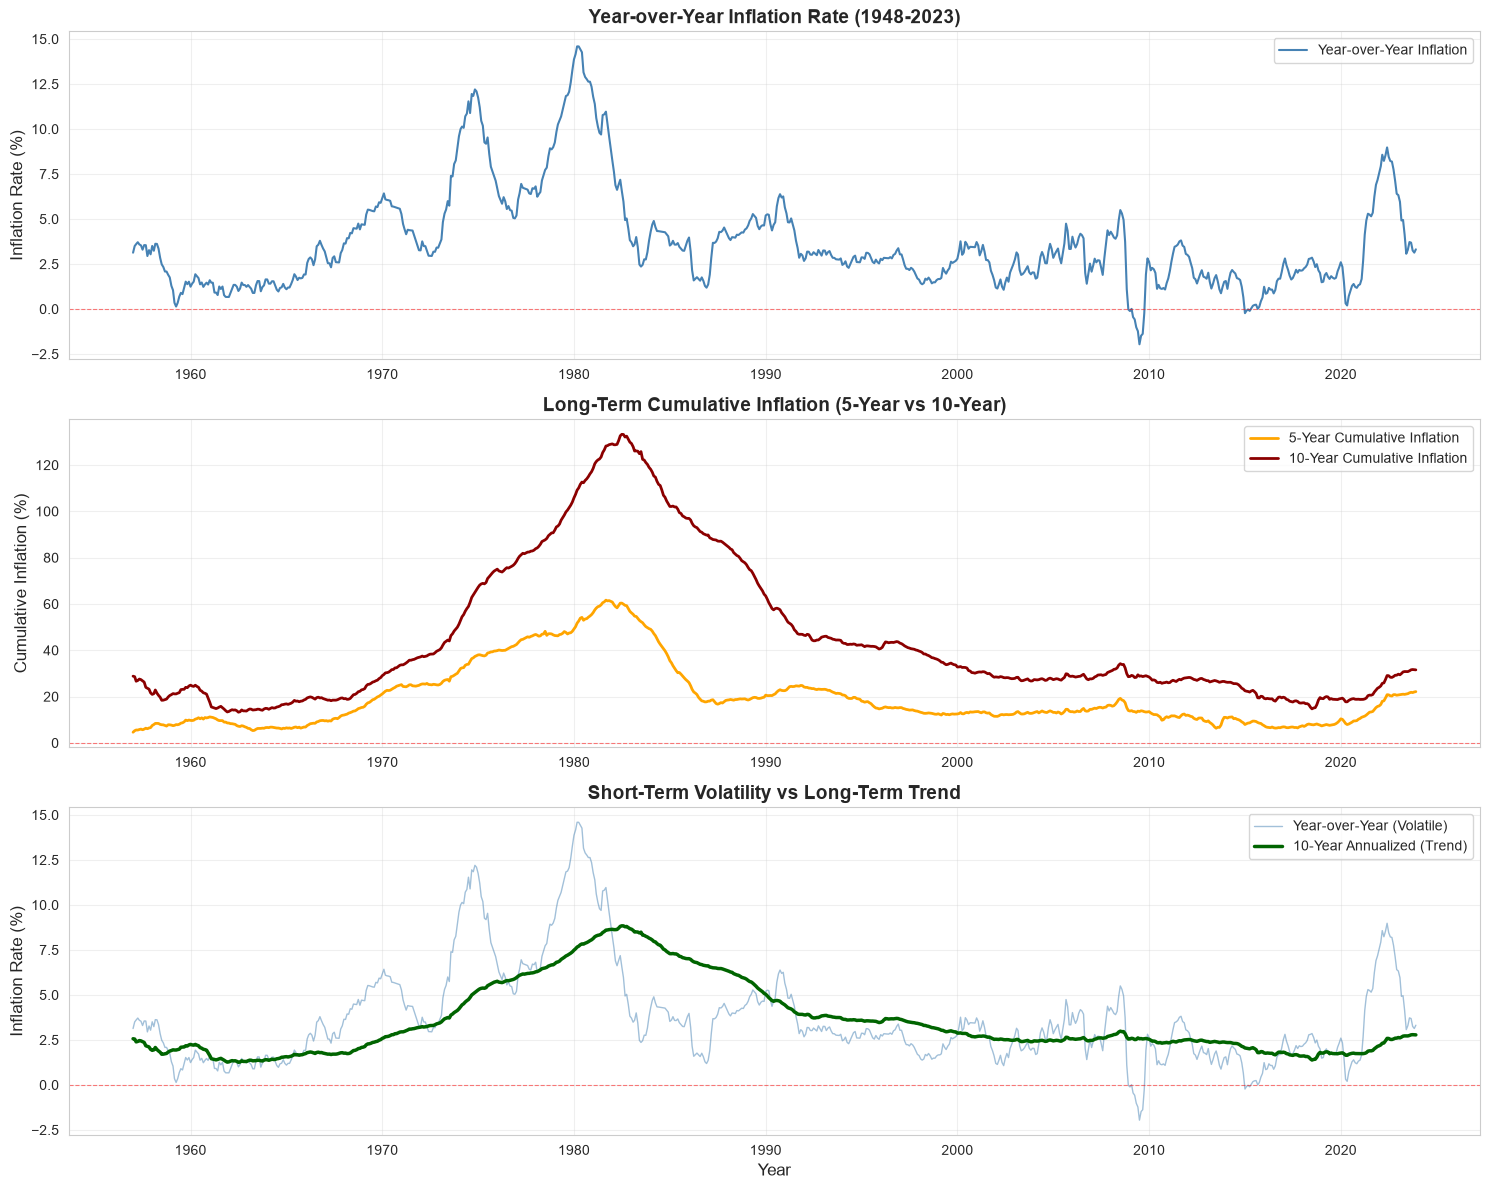

In [7]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 10)

# Create figure with subplots
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Filter out NaN values for cleaner plots
df_clean = df.dropna(subset=['Inflation_YoY', 'Inflation_5Y', 'Inflation_10Y']).copy()

# ===== Plot 1: Year-over-Year Inflation (Standard Metric) =====
axes[0].plot(df_clean['date'], df_clean['Inflation_YoY'],
             color='steelblue', linewidth=1.5, label='Year-over-Year Inflation')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_title('Year-over-Year Inflation Rate (1948-2023)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Inflation Rate (%)', fontsize=12)
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# ===== Plot 2: 5-Year vs 10-Year Cumulative Inflation =====
axes[1].plot(df_clean['date'], df_clean['Inflation_5Y'],
             color='orange', linewidth=2, label='5-Year Cumulative Inflation')
axes[1].plot(df_clean['date'], df_clean['Inflation_10Y'],
             color='darkred', linewidth=2, label='10-Year Cumulative Inflation')
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=0.8, alpha=0.5)
axes[1].set_title('Long-Term Cumulative Inflation (5-Year vs 10-Year)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Cumulative Inflation (%)', fontsize=12)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# ===== Plot 3: Comparison - YoY vs 10-Year Annualized =====
axes[2].plot(df_clean['date'], df_clean['Inflation_YoY'],
             color='steelblue', linewidth=1, label='Year-over-Year (Volatile)', alpha=0.5)
axes[2].plot(df_clean['date'], df_clean['Inflation_10Y_Annualized'],
             color='darkgreen', linewidth=2.5, label='10-Year Annualized (Trend)')
axes[2].axhline(y=0, color='red', linestyle='--', linewidth=0.8, alpha=0.5)
axes[2].set_title('Short-Term Volatility vs Long-Term Trend', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Year', fontsize=12)
axes[2].set_ylabel('Inflation Rate (%)', fontsize=12)
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('inflation_analysis_complete.png', dpi=300, bbox_inches='tight')
plt.show()

## Decade-by-Decade Comparison:

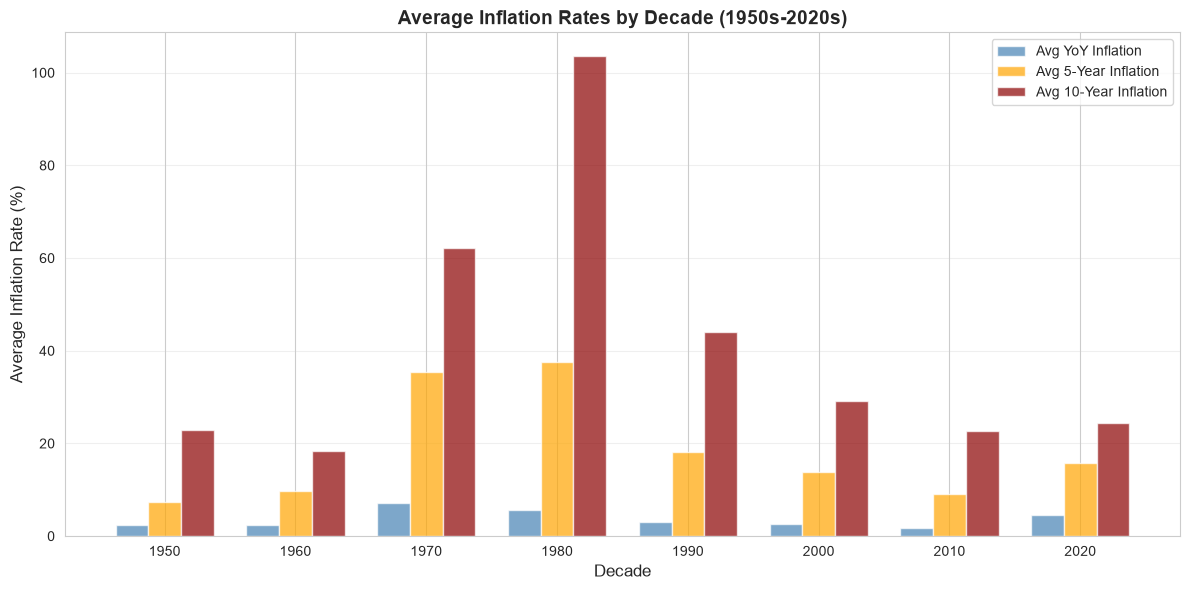

In [8]:
# Create decade comparison
df_clean['decade'] = (df_clean['date'].dt.year // 10) * 10

# Average inflation by decade
decade_summary = df_clean.groupby('decade').agg({
    'Inflation_YoY': 'mean',
    'Inflation_5Y': 'mean',
    'Inflation_10Y': 'mean'
}).reset_index()

# Bar chart
fig, ax = plt.subplots(figsize=(12, 6))
x = decade_summary['decade']
width = 2.5

ax.bar(x - width, decade_summary['Inflation_YoY'], width,
       label='Avg YoY Inflation', color='steelblue', alpha=0.7)
ax.bar(x, decade_summary['Inflation_5Y'], width,
       label='Avg 5-Year Inflation', color='orange', alpha=0.7)
ax.bar(x + width, decade_summary['Inflation_10Y'], width,
       label='Avg 10-Year Inflation', color='darkred', alpha=0.7)

ax.set_xlabel('Decade', fontsize=12)
ax.set_ylabel('Average Inflation Rate (%)', fontsize=12)
ax.set_title('Average Inflation Rates by Decade (1950s-2020s)', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('inflation_by_decade.png', dpi=300, bbox_inches='tight')
plt.show()

## Summary Statistics:

In [9]:
# Print summary statistics
print("\n===== INFLATION SUMMARY STATISTICS =====\n")
print("Year-over-Year Inflation:")
print(df_clean['Inflation_YoY'].describe())

print("\n5-Year Cumulative Inflation:")
print(df_clean['Inflation_5Y'].describe())

print("\n10-Year Cumulative Inflation:")
print(df_clean['Inflation_10Y'].describe())

print("\n===== DECADE AVERAGES =====")
print(decade_summary)


===== INFLATION SUMMARY STATISTICS =====

Year-over-Year Inflation:
count    804.000000
mean       3.708972
std        2.788643
min       -1.958761
25%        1.754042
50%        3.017058
75%        4.595829
max       14.592275
Name: Inflation_YoY, dtype: float64

5-Year Cumulative Inflation:
count    804.000000
mean      19.723066
std       13.868748
min        4.612476
25%       10.199922
50%       14.224881
75%       23.570606
max       61.631944
Name: Inflation_5Y, dtype: float64

10-Year Cumulative Inflation:
count    804.000000
mean      44.263460
std       31.088625
min       13.268366
25%       22.777030
50%       29.859000
75%       54.700443
max      133.253589
Name: Inflation_10Y, dtype: float64

===== DECADE AVERAGES =====
   decade  Inflation_YoY  Inflation_5Y  Inflation_10Y
0    1950       2.353976      7.406896      22.837234
1    1960       2.334269      9.777809      18.406436
2    1970       7.090586     35.339403      62.167851
3    1980       5.559376     37.511300

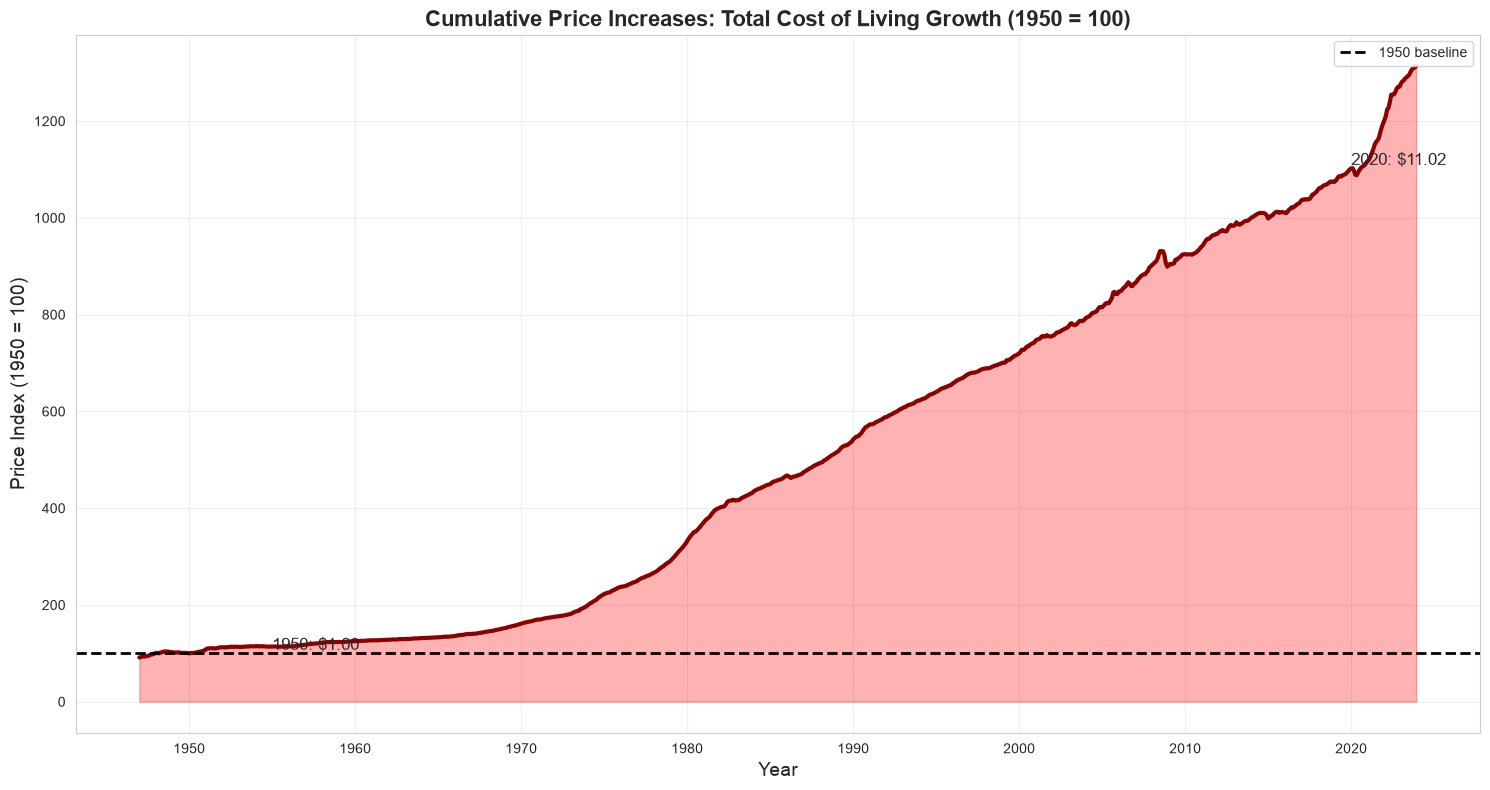

In [10]:
# Calculate cumulative inflation from base year (1950 = 100)
base_year_cpi = df[df['date'].dt.year == 1950]['value'].iloc[0]
df['CPI_Indexed'] = (df['value'] / base_year_cpi) * 100

# This shows TOTAL price increase since 1950
fig, ax = plt.subplots(figsize=(15, 8))
ax.plot(df['date'], df['CPI_Indexed'], linewidth=3, color='darkred')
ax.fill_between(df['date'], 0, df['CPI_Indexed'], alpha=0.3, color='red')
ax.set_title('Cumulative Price Increases: Total Cost of Living Growth (1950 = 100)',
             fontsize=16, fontweight='bold')
ax.set_ylabel('Price Index (1950 = 100)', fontsize=14)
ax.set_xlabel('Year', fontsize=14)
ax.grid(True, alpha=0.3)

# Add annotations
ax.axhline(y=100, color='black', linestyle='--', linewidth=2, label='1950 baseline')
ax.text(pd.Timestamp('1955-01-01'), 100, '1950: $1.00', fontsize=12, va='bottom')
ax.text(pd.Timestamp('2020-01-01'), df[df['date'].dt.year == 2020]['CPI_Indexed'].iloc[0],
        f'2020: ${df[df["date"].dt.year == 2020]["CPI_Indexed"].iloc[0]/100:.2f}',
        fontsize=12, va='bottom')

plt.legend()
plt.tight_layout()
plt.savefig('cumulative_cost_of_living.png', dpi=300)
plt.show()

# This graph will show an ever-increasing line that DOESN'T go down
#---
## **Why Inflation Rates Decreased But Costs Keep Rising:**

### **1. Compounding Effect**
# Even low inflation compounds on an already-high base:
# - 1980: 3% inflation on $10 item = $0.30 increase → $10.30
# - 2023: 3% inflation on $100 item = $3.00 increase → $103.00
# - **Same rate (3%), but $3 increase vs $0.30 increase!**

### **2. The Fed's "Success" Story**
# The Federal Reserve views the 1980s spike as a crisis they "solved":
# - Paul Volcker raised interest rates to 20% to "break" inflation
# - They succeeded in lowering the RATE of inflation
# - But prices never went back down (deflation is rare)
# - **Lower rate ≠ lower prices, just slower increases**

### **3. Wage Growth Didn't Keep Up**
# 1980: Median wage $12,000, Median home $64,000 (5.3x income)
# 2023: Median wage $56,000, Median home $420,000 (7.5x income)

## Real vs Nominal Comparison

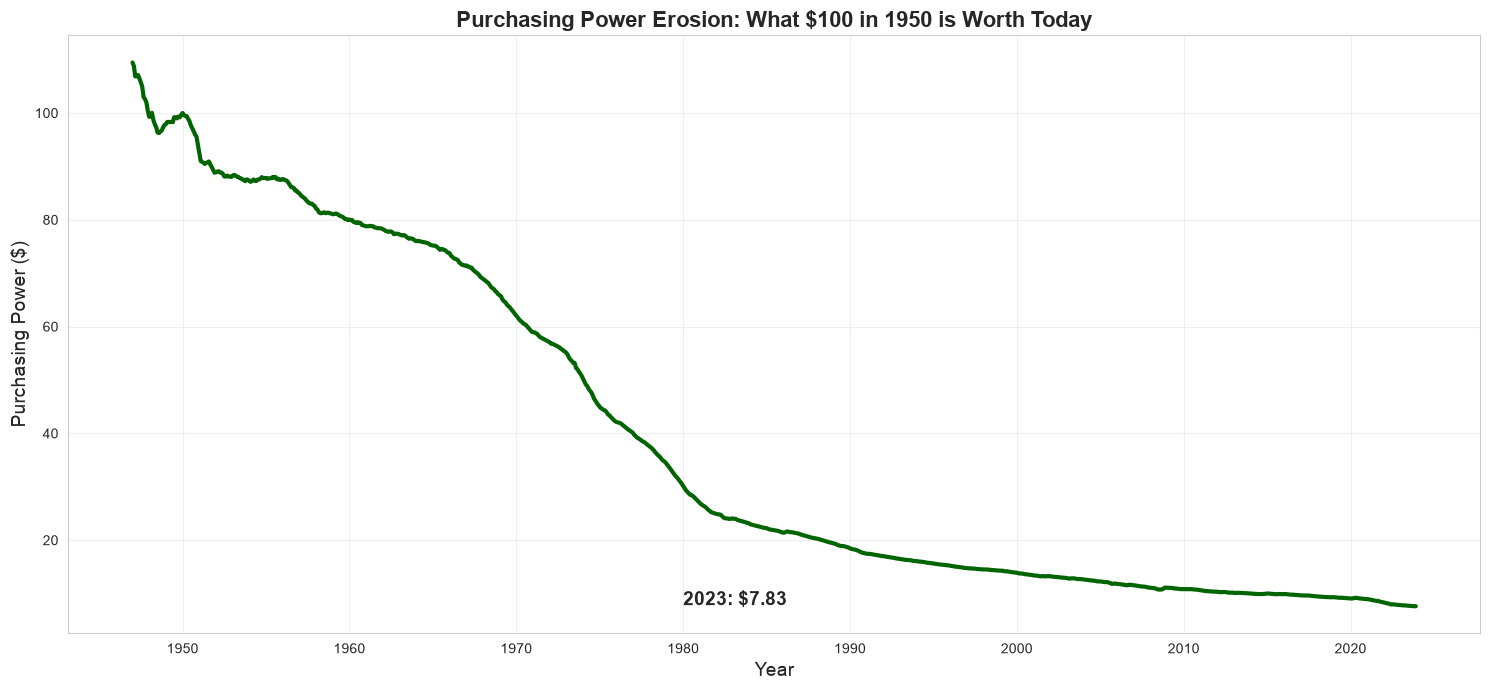

In [11]:
# Show purchasing power decline
df['Purchasing_Power'] = 100 / (df['value'] / base_year_cpi)

plt.figure(figsize=(15, 7))
plt.plot(df['date'], df['Purchasing_Power'], linewidth=3, color='darkgreen')
plt.title('Purchasing Power Erosion: What $100 in 1950 is Worth Today',
          fontsize=16, fontweight='bold')
plt.ylabel('Purchasing Power ($)', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.grid(True, alpha=0.3)

# Add annotation showing $100 in 1950 = $X today
current_value = df[df['date'].dt.year == 2023]['Purchasing_Power'].iloc[0]
plt.text(pd.Timestamp('1980-01-01'), current_value, f'2023: ${current_value:.2f}', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## Military Spending Analysis and Trends

*Exploratory analysis of US defense expenditures over time*

MILITARY SPENDING SUMMARY STATISTICS (1947-2023)

Total Military Spending (Cumulative): $26,879 Billion
Average Annual Spending: $349.08 Billion
Median Annual Spending: $329.50 Billion
Peak Annual Spending: $1002.56 Billion (2023)
Lowest Annual Spending: $20.89 Billion (1948)

AVERAGE MILITARY SPENDING BY DECADE
1940s: $21.43 Billion
1950s: $52.98 Billion
1960s: $78.64 Billion
1970s: $119.51 Billion
1980s: $304.06 Billion
1990s: $387.77 Billion
2000s: $582.32 Billion
2010s: $783.72 Billion
2020s: $931.17 Billion


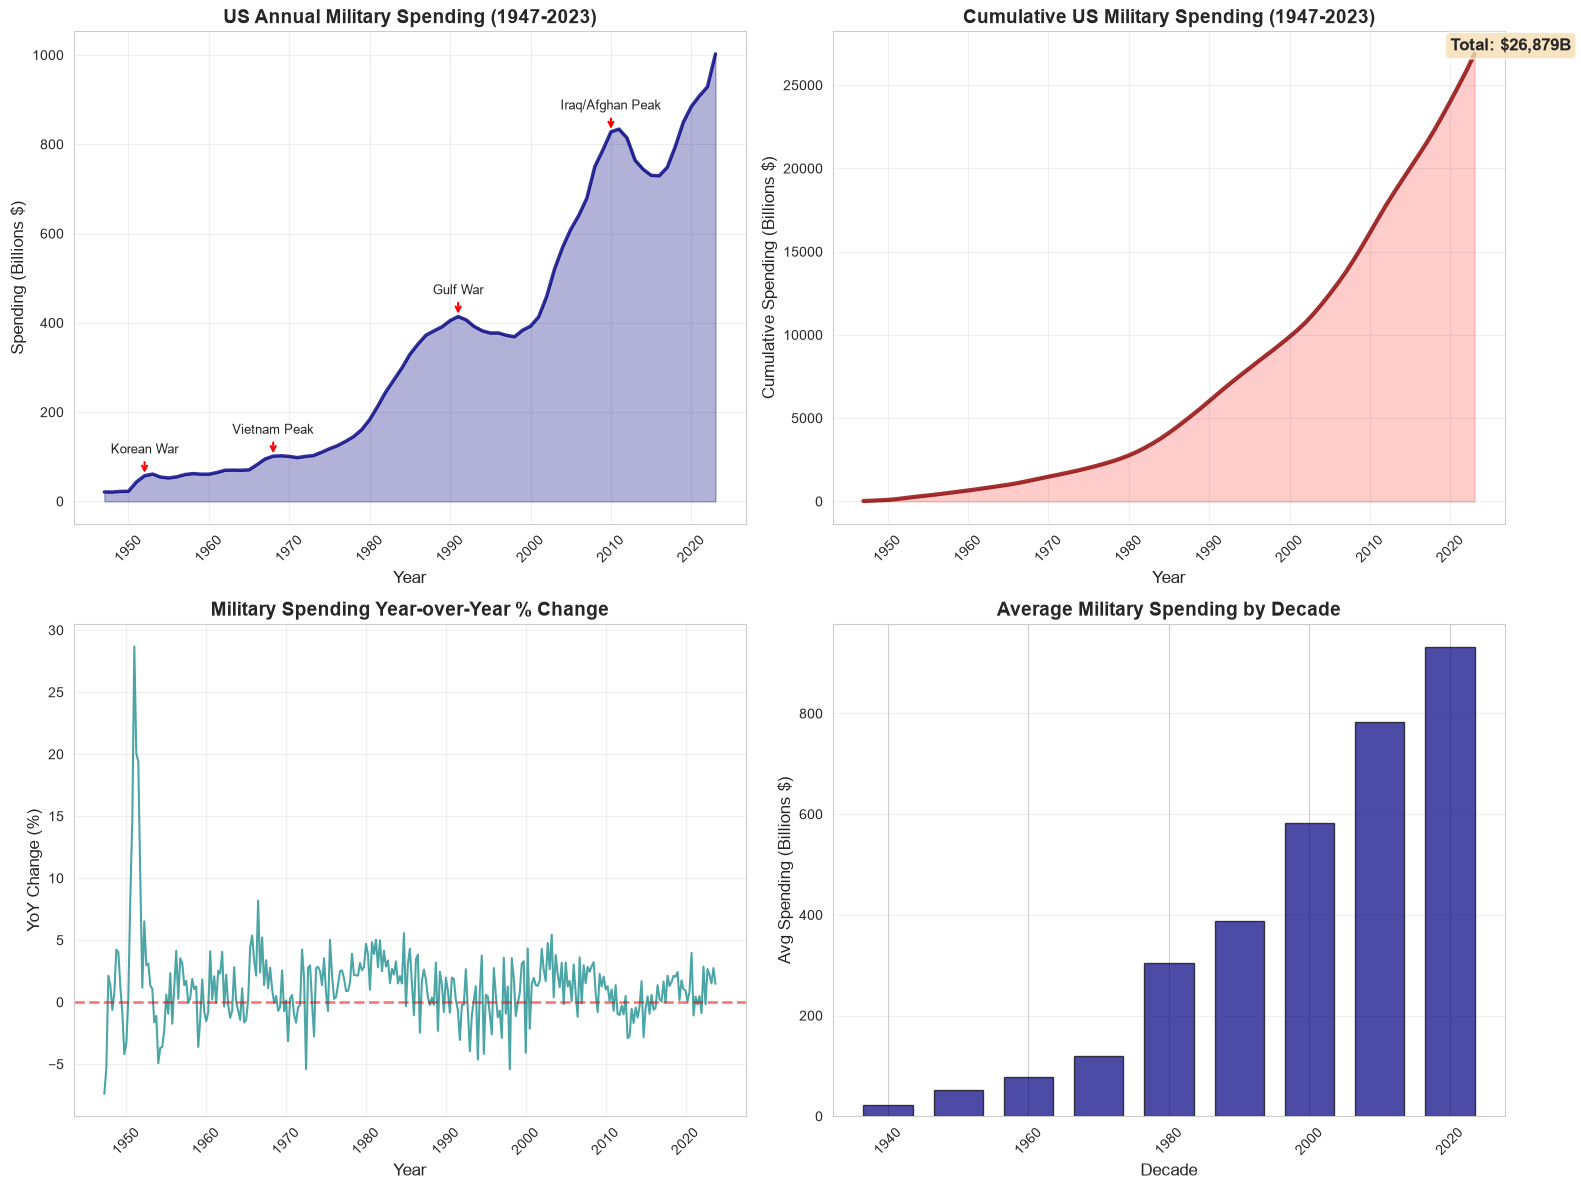

In [12]:
# ============================================================================
# SECTION 2: Military Spending Analysis and Trends
# ============================================================================

# Load military spending data
military_df = pd.read_excel('FDEFX.xlsx')
military_df['observation_date'] = pd.to_datetime(military_df['observation_date'])
military_df = military_df.sort_values('observation_date').reset_index(drop=True)

# Calculate year and decade
military_df['year'] = military_df['observation_date'].dt.year
military_df['decade'] = (military_df['year'] // 10) * 10

# Calculate year-over-year change
military_df['Military_YoY_Change'] = military_df['FDEFX'].pct_change() * 100

# Calculate 5-year and 10-year changes (FDEFX is quarterly: 20 quarters = 5 yrs, 40 = 10 yrs)
military_df['Military_5Y_Change'] = ((military_df['FDEFX'] - military_df['FDEFX'].shift(20)) / military_df['FDEFX'].shift(20)) * 100
military_df['Military_10Y_Change'] = ((military_df['FDEFX'] - military_df['FDEFX'].shift(40)) / military_df['FDEFX'].shift(40)) * 100

# Resample to annual for cleaner analysis
military_annual = military_df.groupby('year').agg({
    'FDEFX': 'mean'
}).reset_index()

# Calculate cumulative spending
military_annual['Cumulative_Spending'] = military_annual['FDEFX'].cumsum()

print("="*70)
print("MILITARY SPENDING SUMMARY STATISTICS (1947-2023)")
print("="*70)
print(f"\nTotal Military Spending (Cumulative): ${military_annual['Cumulative_Spending'].iloc[-1]:,.0f} Billion")
print(f"Average Annual Spending: ${military_annual['FDEFX'].mean():.2f} Billion")
print(f"Median Annual Spending: ${military_annual['FDEFX'].median():.2f} Billion")
print(f"Peak Annual Spending: ${military_annual['FDEFX'].max():.2f} Billion ({military_annual.loc[military_annual['FDEFX'].idxmax(), 'year']})")
print(f"Lowest Annual Spending: ${military_annual['FDEFX'].min():.2f} Billion ({military_annual.loc[military_annual['FDEFX'].idxmin(), 'year']})")

# Decade analysis
decade_military = military_df.groupby('decade')['FDEFX'].mean().reset_index()

print("\n" + "="*70)
print("AVERAGE MILITARY SPENDING BY DECADE")
print("="*70)
for _, row in decade_military.iterrows():
    print(f"{int(row['decade'])}s: ${row['FDEFX']:.2f} Billion")

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Annual Military Spending Over Time
axes[0, 0].plot(military_annual['year'], military_annual['FDEFX'],
                linewidth=2.5, color='navy', alpha=0.8)
axes[0, 0].fill_between(military_annual['year'], 0, military_annual['FDEFX'],
                        alpha=0.3, color='navy')
axes[0, 0].set_title('US Annual Military Spending (1947-2023)',
                     fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Spending (Billions $)', fontsize=12)
axes[0, 0].set_xlabel('Year', fontsize=12)
axes[0, 0].grid(True, alpha=0.3)

# Add major war annotations
wars = {
    1952: 'Korean War',
    1968: 'Vietnam Peak',
    1991: 'Gulf War',
    2010: 'Iraq/Afghan Peak'
}
for year, label in wars.items():
    if year in military_annual['year'].values:
        value = military_annual[military_annual['year'] == year]['FDEFX'].iloc[0]
        axes[0, 0].annotate(label, xy=(year, value),
                            xytext=(year, value + 50),
                            fontsize=9, ha='center',
                            arrowprops=dict(arrowstyle='->', color='red', lw=1.5))

# Plot 2: Cumulative Military Spending
axes[0, 1].plot(military_annual['year'], military_annual['Cumulative_Spending'],
                linewidth=3, color='darkred', alpha=0.8)
axes[0, 1].fill_between(military_annual['year'], 0, military_annual['Cumulative_Spending'],
                        alpha=0.2, color='red')
axes[0, 1].set_title('Cumulative US Military Spending (1947-2023)',
                     fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Cumulative Spending (Billions $)', fontsize=12)
axes[0, 1].set_xlabel('Year', fontsize=12)
axes[0, 1].grid(True, alpha=0.3)

# Add annotation for total
total = military_annual['Cumulative_Spending'].iloc[-1]
axes[0, 1].text(2020, total, f'Total: ${total:,.0f}B',
                fontsize=12, fontweight='bold', va='bottom',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Plot 3: Year-over-Year % Change
axes[1, 0].plot(military_df['observation_date'], military_df['Military_YoY_Change'],
                linewidth=1.5, color='teal', alpha=0.7)
axes[1, 0].axhline(y=0, color='red', linestyle='--', linewidth=2, alpha=0.5)
axes[1, 0].set_title('Military Spending Year-over-Year % Change',
                     fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('YoY Change (%)', fontsize=12)
axes[1, 0].set_xlabel('Year', fontsize=12)
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Decade Comparison
axes[1, 1].bar(decade_military['decade'], decade_military['FDEFX'],
               width=7, color='navy', alpha=0.7, edgecolor='black')
axes[1, 1].set_title('Average Military Spending by Decade',
                     fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Avg Spending (Billions $)', fontsize=12)
axes[1, 1].set_xlabel('Decade', fontsize=12)
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Rotate x-labels
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('military_spending_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

## Comparative Analysis: Inflation vs Military Spending

*Visual correlation between cost of living and defense expenditures*

MERGED DATASET SUMMARY
Date Range: 1947 - 2023
Total Observations: 77

Key Metrics:
  Cost of Living increased: 1318.5%
  Military Spending increased: 4657.6%
  Purchasing Power Lost: 93.0%


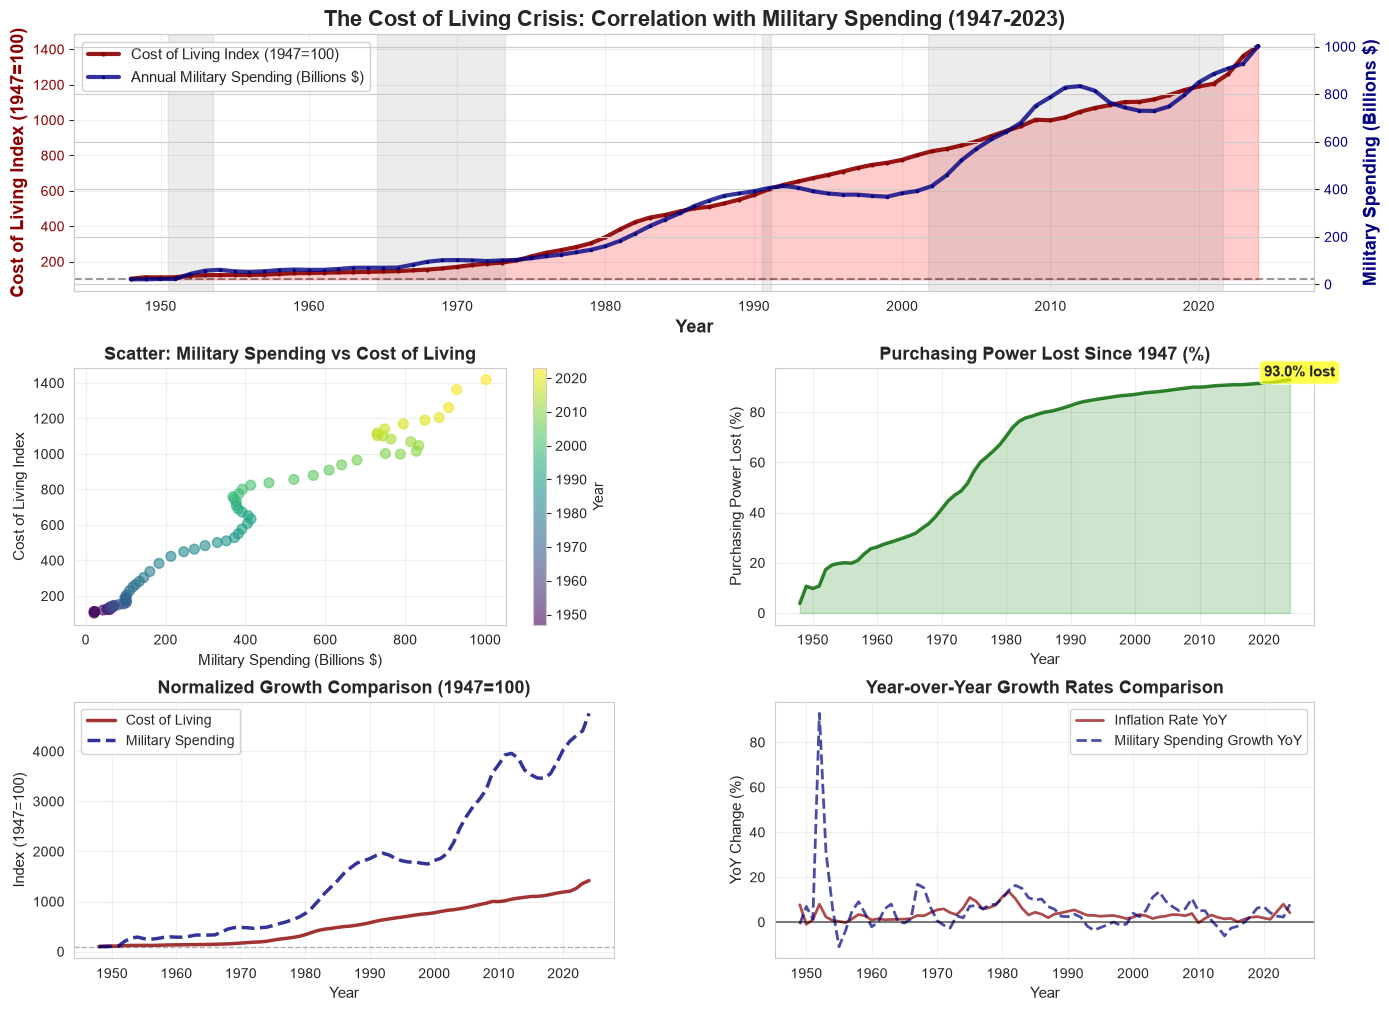


✓ Merged dataset saved as 'merged_inflation_military.xlsx'


In [15]:
# ============================================================================
# SECTION 3: Comparative Analysis - Inflation vs Military Spending
# ============================================================================


# Load both datasets
inflation_df = pd.read_excel('US_inflation_calculated.xlsx')  # Your processed file
military_df = pd.read_excel('FDEFX.xlsx')

# Process dates
inflation_df['date'] = pd.to_datetime(inflation_df['date'])
military_df['observation_date'] = pd.to_datetime(military_df['observation_date'])

# Calculate CPI indexed to 1947 = 100
base_cpi = inflation_df[inflation_df['date'].dt.year == 1947]['value'].iloc[0]
inflation_df['CPI_Indexed'] = (inflation_df['value'] / base_cpi) * 100

# Resample to annual
inflation_annual = inflation_df.set_index('date').resample('YE').mean().reset_index()
military_annual = military_df.set_index('observation_date').resample('YE').mean().reset_index()

# Rename columns for clarity
inflation_annual.rename(columns={'date': 'year'}, inplace=True)
military_annual.rename(columns={'observation_date': 'year'}, inplace=True)

# Merge datasets
merged_df = pd.merge(inflation_annual, military_annual, on='year', how='inner')

# Calculate additional metrics
merged_df['year_num'] = merged_df['year'].dt.year
merged_df['Purchasing_Power_Loss'] = 100 - (100 / (merged_df['value'] / base_cpi))

print("="*70)
print("MERGED DATASET SUMMARY")
print("="*70)
print(f"Date Range: {merged_df['year_num'].min()} - {merged_df['year_num'].max()}")
print(f"Total Observations: {len(merged_df)}")
print(f"\nKey Metrics:")
print(f"  Cost of Living increased: {merged_df['CPI_Indexed'].iloc[-1] - 100:.1f}%")
print(f"  Military Spending increased: {((merged_df['FDEFX'].iloc[-1] / merged_df['FDEFX'].iloc[0]) - 1) * 100:.1f}%")
print(f"  Purchasing Power Lost: {merged_df['Purchasing_Power_Loss'].iloc[-1]:.1f}%")

# ===== VISUALIZATION: Cost of Living Crisis Chart =====
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# Main plot: Dual axis comparison
ax1 = fig.add_subplot(gs[0, :])
ax1_twin = ax1.twinx()

# Cost of Living (left axis)
line1 = ax1.plot(merged_df['year'], merged_df['CPI_Indexed'],
                 linewidth=3, color='darkred', label='Cost of Living Index (1947=100)',
                 alpha=0.9, marker='o', markersize=2)
ax1.fill_between(merged_df['year'], 100, merged_df['CPI_Indexed'],
                 alpha=0.2, color='red')

# Military Spending (right axis)
line2 = ax1_twin.plot(merged_df['year'], merged_df['FDEFX'],
                      linewidth=3, color='navy', label='Annual Military Spending (Billions $)',
                      alpha=0.8, marker='s', markersize=2)

ax1.axhline(y=100, color='black', linestyle='--', linewidth=1.5, alpha=0.4)
ax1.set_title('The Cost of Living Crisis: Correlation with Military Spending (1947-2023)',
              fontsize=16, fontweight='bold')
ax1.set_xlabel('Year', fontsize=13, fontweight='bold')
ax1.set_ylabel('Cost of Living Index (1947=100)', fontsize=13, color='darkred', fontweight='bold')
ax1_twin.set_ylabel('Military Spending (Billions $)', fontsize=13, color='navy', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='darkred')
ax1_twin.tick_params(axis='y', labelcolor='navy')

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=11, framealpha=0.9)
ax1.grid(True, alpha=0.3)

# Add war period shading
war_periods = [
    (pd.Timestamp('1950-06-25'), pd.Timestamp('1953-07-27'), 'Korean War', 0.15),
    (pd.Timestamp('1964-08-02'), pd.Timestamp('1973-03-29'), 'Vietnam War', 0.15),
    (pd.Timestamp('1990-08-02'), pd.Timestamp('1991-02-28'), 'Gulf War', 0.15),
    (pd.Timestamp('2001-10-07'), pd.Timestamp('2021-08-30'), 'War on Terror', 0.15)
]

for start, end, label, alpha_val in war_periods:
    ax1.axvspan(start, end, alpha=alpha_val, color='gray')

# Plot 2: Scatter plot with trend line
ax2 = fig.add_subplot(gs[1, 0])
ax2.scatter(merged_df['FDEFX'], merged_df['CPI_Indexed'],
            alpha=0.6, s=50, c=merged_df['year_num'], cmap='viridis')
ax2.set_title('Scatter: Military Spending vs Cost of Living',
              fontsize=13, fontweight='bold')
ax2.set_xlabel('Military Spending (Billions $)', fontsize=11)
ax2.set_ylabel('Cost of Living Index', fontsize=11)
ax2.grid(True, alpha=0.3)

# Add colorbar for years
cbar = plt.colorbar(ax2.collections[0], ax=ax2)
cbar.set_label('Year', fontsize=10)

# Plot 3: Purchasing Power Loss
# NOTE: the setup lines for this panel were missing in the original notebook;
# they have been reconstructed so the cell runs.
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(merged_df['year'], merged_df['Purchasing_Power_Loss'],
         linewidth=2.5, color='darkgreen', alpha=0.8)
ax3.fill_between(merged_df['year'], 0, merged_df['Purchasing_Power_Loss'],
                 alpha=0.2, color='green')
ax3.set_title('Purchasing Power Lost Since 1947 (%)', fontsize=13, fontweight='bold')
ax3.set_xlabel('Year', fontsize=11)
ax3.set_ylabel('Purchasing Power Lost (%)', fontsize=11)
ax3.grid(True, alpha=0.3)
final_loss = merged_df['Purchasing_Power_Loss'].iloc[-1]
ax3.text(merged_df['year'].iloc[-5], final_loss,
         f'{final_loss:.1f}% lost',
         fontsize=11, fontweight='bold', va='bottom',
         bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7))

# Plot 4: Normalized comparison (both starting at 100)
ax4 = fig.add_subplot(gs[2, 0])
military_indexed = (merged_df['FDEFX'] / merged_df['FDEFX'].iloc[0]) * 100
ax4.plot(merged_df['year'], merged_df['CPI_Indexed'],
         linewidth=2.5, color='darkred', label='Cost of Living', alpha=0.8)
ax4.plot(merged_df['year'], military_indexed,
         linewidth=2.5, color='navy', label='Military Spending', alpha=0.8, linestyle='--')
ax4.axhline(y=100, color='black', linestyle='--', linewidth=1, alpha=0.3)
ax4.set_title('Normalized Growth Comparison (1947=100)',
              fontsize=13, fontweight='bold')
ax4.set_xlabel('Year', fontsize=11)
ax4.set_ylabel('Index (1947=100)', fontsize=11)
ax4.legend(fontsize=10)
ax4.grid(True, alpha=0.3)

# Plot 5: Rate of change comparison
ax5 = fig.add_subplot(gs[2, 1])
inflation_yoy = merged_df['Inflation_YoY'].dropna()
military_yoy = merged_df['FDEFX'].pct_change() * 100

# Fix: Make sure both arrays have the same length and align with the years
# Get common indices where both have values
common_indices = inflation_yoy.index.intersection(military_yoy.index)
years_to_plot = merged_df['year'].loc[common_indices]

ax5.plot(years_to_plot, inflation_yoy.loc[common_indices],
         linewidth=2, color='darkred', label='Inflation Rate YoY', alpha=0.7)
ax5.plot(years_to_plot, military_yoy.loc[common_indices],
         linewidth=2, color='navy', label='Military Spending Growth YoY', alpha=0.7, linestyle='--')
ax5.axhline(y=0, color='black', linestyle='-', linewidth=1.5, alpha=0.5)
ax5.set_title('Year-over-Year Growth Rates Comparison',
              fontsize=13, fontweight='bold')
ax5.set_xlabel('Year', fontsize=11)
ax5.set_ylabel('YoY Change (%)', fontsize=11)
ax5.legend(fontsize=10)
ax5.grid(True, alpha=0.3)

plt.savefig('comparative_analysis_inflation_military.png', dpi=300, bbox_inches='tight')
plt.show()

# Save merged dataset for regression analysis
merged_df.to_excel('merged_inflation_military.xlsx', index=False)
print("\n✓ Merged dataset saved as 'merged_inflation_military.xlsx'")

## Statistical Modeling and Correlation Analysis

*Quantifying relationships through linear regression and statistical tests*

CORRELATION ANALYSIS

1. Pearson Correlation (Military Spending vs Cost of Living):
   Correlation coefficient (r): 0.9830
   P-value: 2.93e-56
   R-squared: 0.9664
   ✓ HIGHLY SIGNIFICANT (p < 0.001)
   → 96.6% of cost of living variation explained by military spending

2. Spearman Correlation (Military Spending vs Cost of Living):
   Correlation coefficient (ρ): 0.9864
   P-value: 8.46e-60

3. Full Correlation Matrix:
                        FDEFX  CPI_Indexed  Inflation_YoY  \
FDEFX                  1.0000       0.9830        -0.1716   
CPI_Indexed            0.9830       1.0000        -0.1511   
Inflation_YoY         -0.1716      -0.1511         1.0000   
Purchasing_Power_Loss  0.8262       0.8703         0.0831   

                       Purchasing_Power_Loss  
FDEFX                                 0.8262  
CPI_Indexed                           0.8703  
Inflation_YoY                         0.0831  
Purchasing_Power_Loss                 1.0000  

LINEAR REGRESSION MODELS

Model 1:

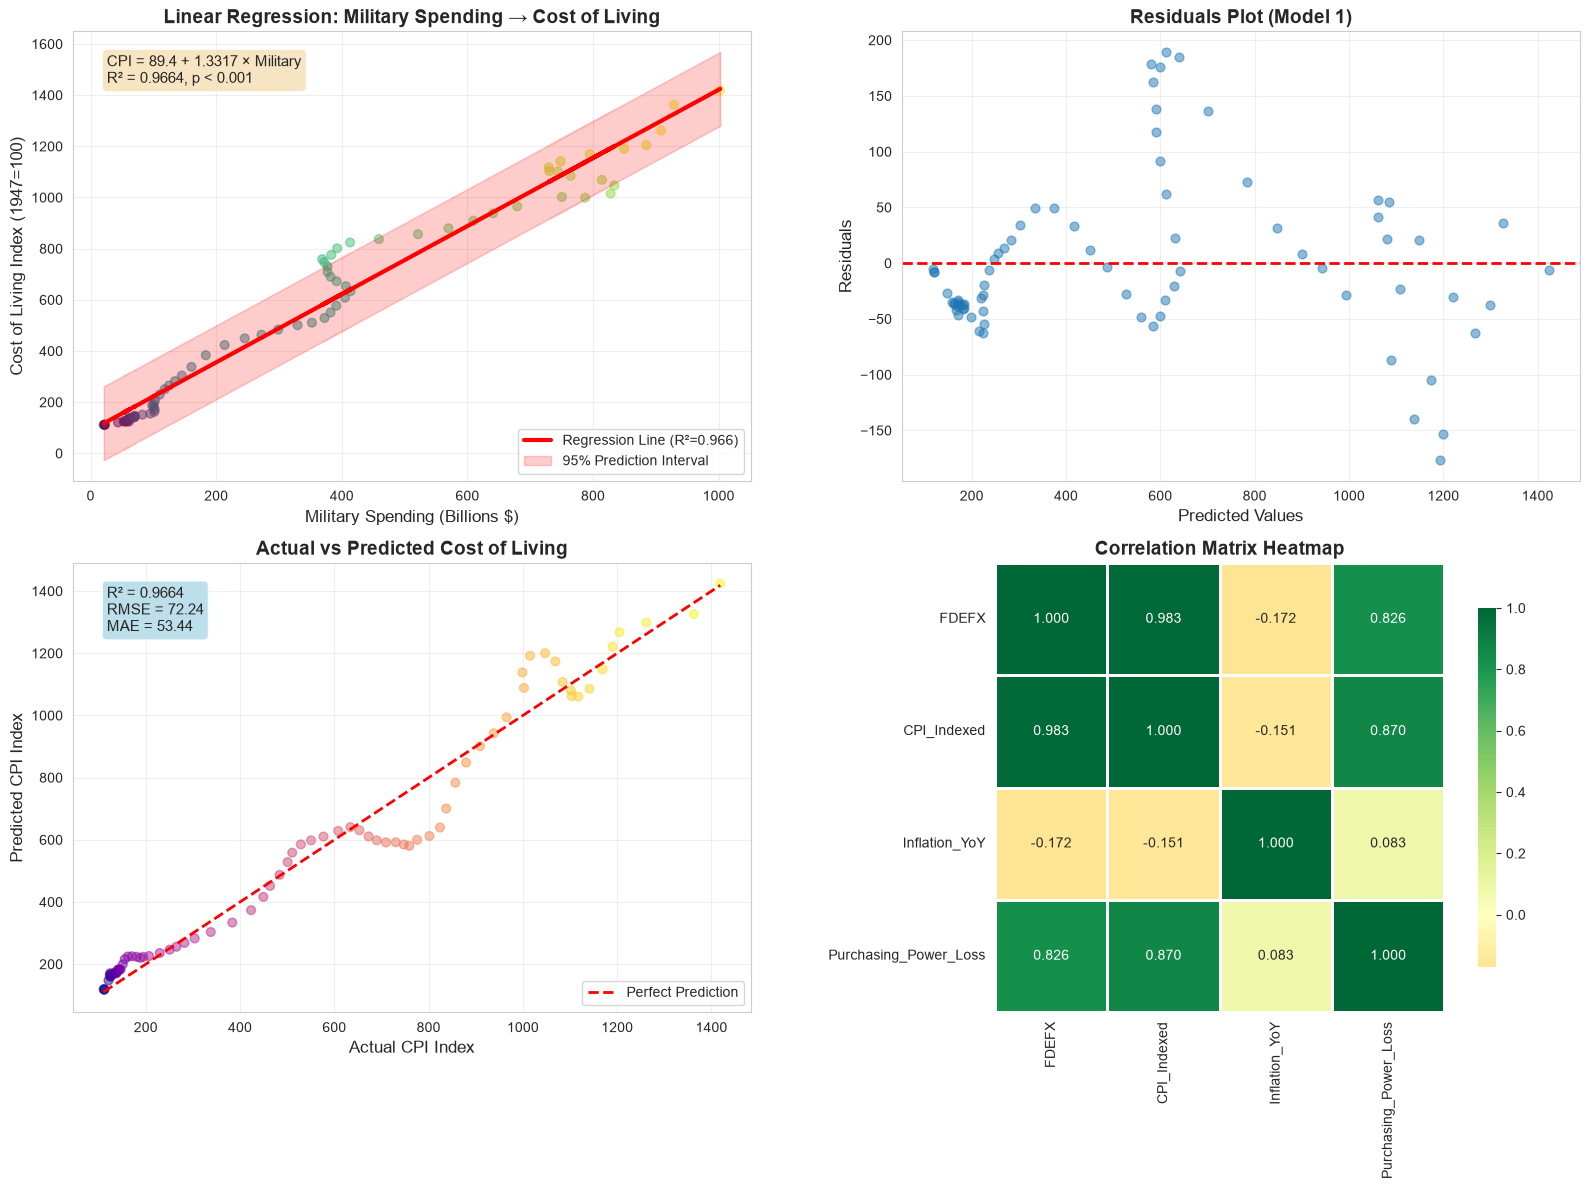

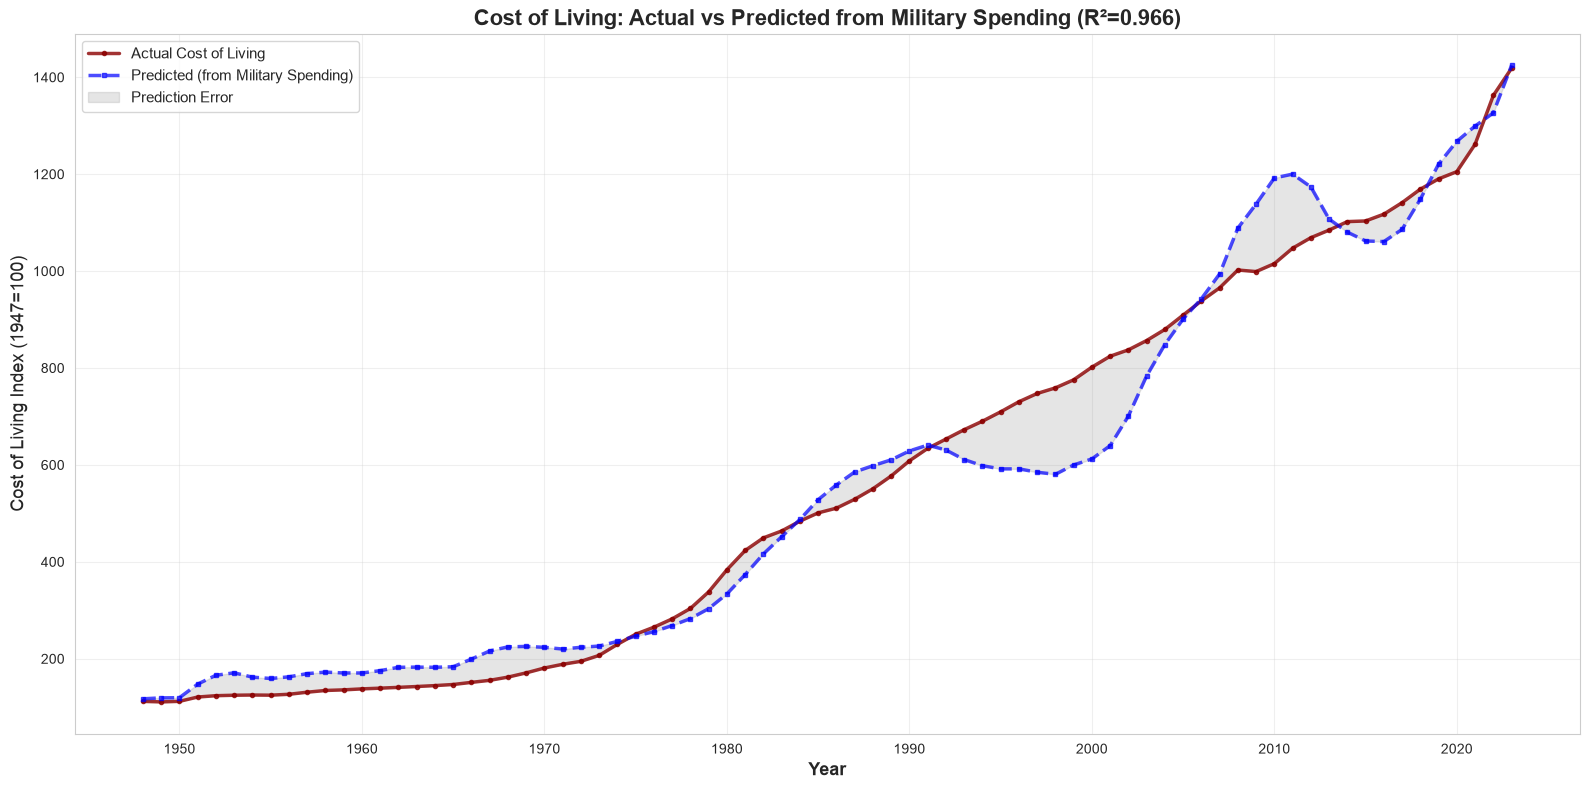


MODEL COMPARISON SUMMARY
                     Model       R²       RMSE         Variables
    Model 1: Simple Linear 0.966359  72.240122 Military Spending
Model 2: Multiple (+ Year) 0.983316   50.87438   Military + Year
     Model 3: Growth Rates 0.107679        N/A      Growth Rates

KEY FINDINGS
✓ Strong positive correlation (r = 0.9830) between military spending and cost of living
✓ Military spending explains 96.6% of cost of living variation
✓ For every $1B increase in military spending, CPI increases by 1.3317 points
✓ Relationship is statistically significant (p < 0.001)
✓ Adding time as control variable improves model fit to R² = 0.9833

GRANGER CAUSALITY TEST
Testing: Does Military Spending 'Granger-cause' Inflation?
(i.e., Do past values of military spending help predict future inflation?)

Testing with lags 1 through 5:

Lag | F-statistic | P-value | Significant?
--------------------------------------------------
  1 |      0.2384 | 0.6268 | ✗ No
  2 |      0.7280 | 0.4865 |

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


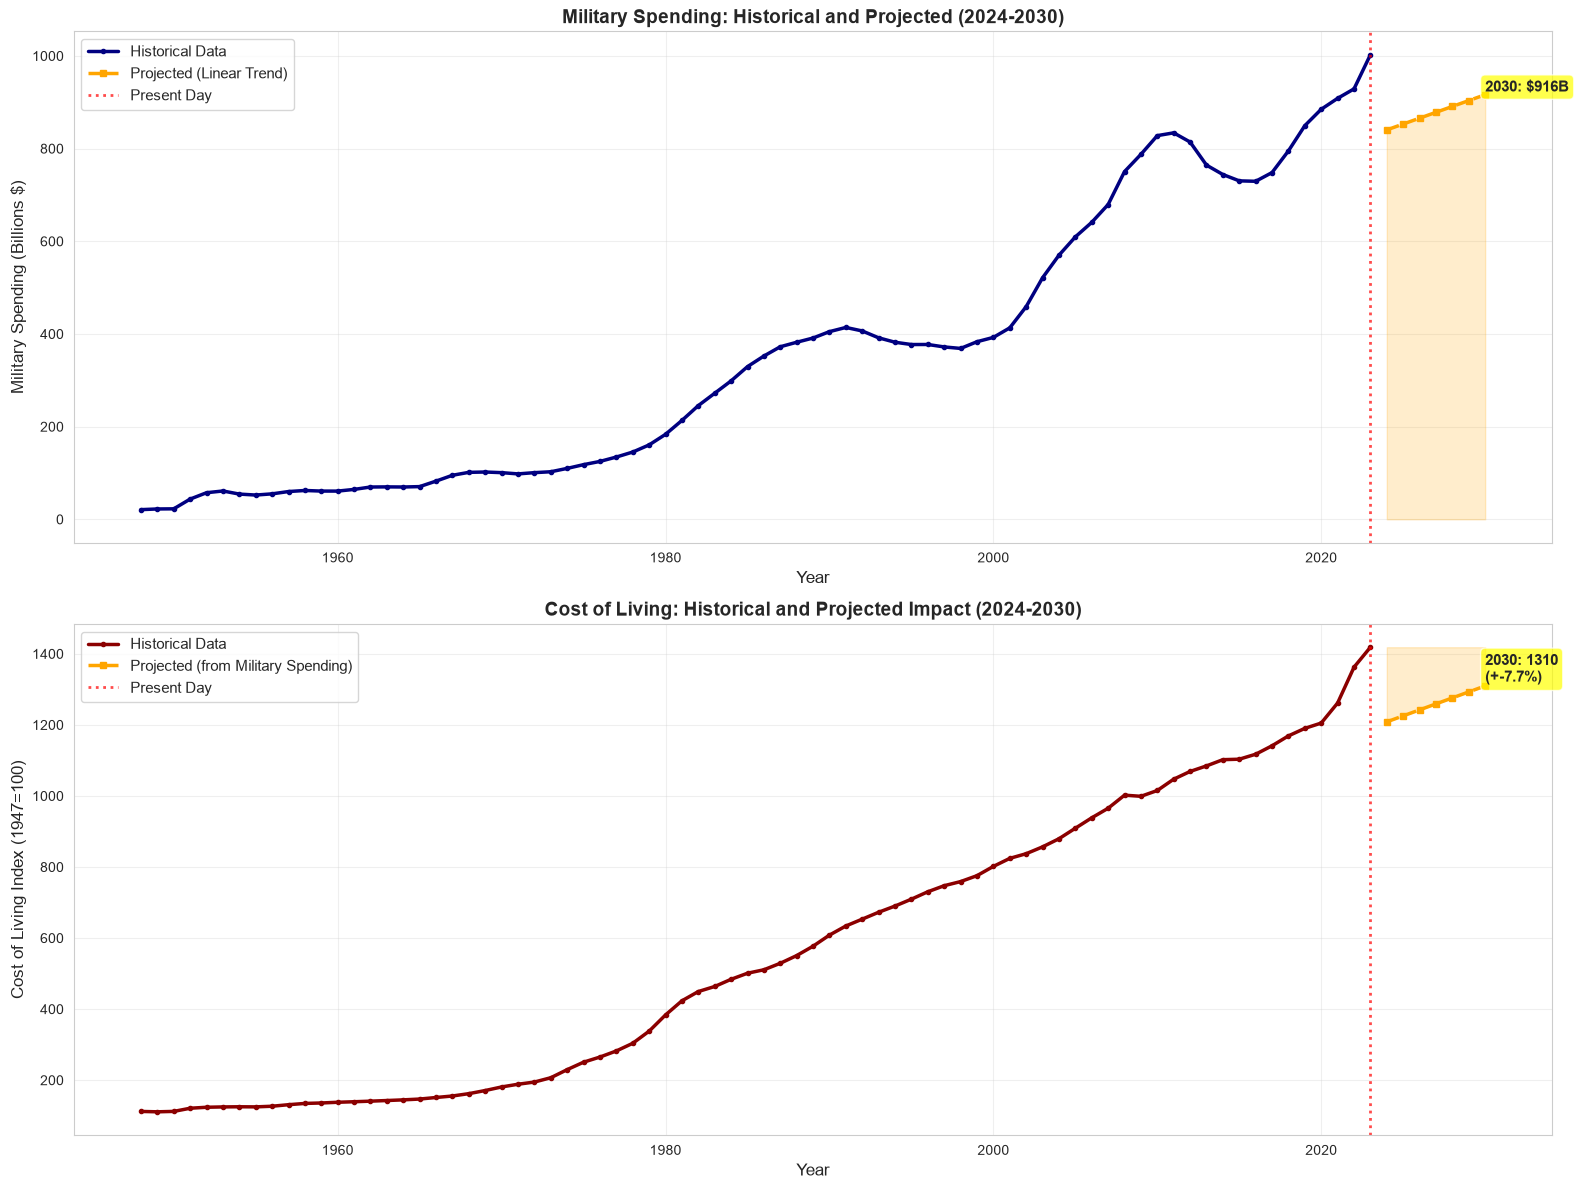


✓ Analysis complete! Files saved:


In [16]:
# ============================================================================
# SECTION 4: Statistical Modeling and Correlation Analysis
# ============================================================================

from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Load merged dataset
merged_df = pd.read_excel('merged_inflation_military.xlsx')
merged_df['year'] = pd.to_datetime(merged_df['year'])
merged_df['year_num'] = merged_df['year'].dt.year

# Remove NaN values
analysis_df = merged_df[['year_num', 'CPI_Indexed', 'FDEFX', 'Inflation_YoY',
                         'Purchasing_Power_Loss']].dropna()

print("="*70)
print("CORRELATION ANALYSIS")
print("="*70)

# ===== 1. PEARSON CORRELATION =====
pearson_corr, pearson_p = stats.pearsonr(analysis_df['FDEFX'], analysis_df['CPI_Indexed'])
print(f"\n1. Pearson Correlation (Military Spending vs Cost of Living):")
print(f"   Correlation coefficient (r): {pearson_corr:.4f}")
print(f"   P-value: {pearson_p:.2e}")
print(f"   R-squared: {pearson_corr**2:.4f}")

if pearson_p < 0.001:
    print("   ✓ HIGHLY SIGNIFICANT (p < 0.001)")
    print(f"   → {abs(pearson_corr**2)*100:.1f}% of cost of living variation explained by military spending")
elif pearson_p < 0.05:
    print("   ✓ SIGNIFICANT (p < 0.05)")
else:
    print("   ✗ Not statistically significant")

# ===== 2. SPEARMAN CORRELATION (non-parametric) =====
spearman_corr, spearman_p = stats.spearmanr(analysis_df['FDEFX'], analysis_df['CPI_Indexed'])
print(f"\n2. Spearman Correlation (Military Spending vs Cost of Living):")
print(f"   Correlation coefficient (ρ): {spearman_corr:.4f}")
print(f"   P-value: {spearman_p:.2e}")

# ===== 3. CORRELATION MATRIX =====
print("\n3. Full Correlation Matrix:")
corr_matrix = analysis_df[['FDEFX', 'CPI_Indexed', 'Inflation_YoY', 'Purchasing_Power_Loss']].corr()
print(corr_matrix.round(4))

# ===== 4. LINEAR REGRESSION ANALYSIS =====
print("\n" + "="*70)
print("LINEAR REGRESSION MODELS")
print("="*70)

# Model 1: Simple Linear Regression (Military Spending → Cost of Living)
X1 = analysis_df[['FDEFX']].values
y1 = analysis_df['CPI_Indexed'].values

model1 = LinearRegression()
model1.fit(X1, y1)
y1_pred = model1.predict(X1)

r2_1 = r2_score(y1, y1_pred)
rmse_1 = np.sqrt(mean_squared_error(y1, y1_pred))
mae_1 = mean_absolute_error(y1, y1_pred)

print(f"\nModel 1: Cost of Living = f(Military Spending)")
print(f"  Equation: CPI = {model1.intercept_:.2f} + {model1.coef_[0]:.4f} × Military_Spending")
print(f"  R-squared: {r2_1:.4f}")
print(f"  RMSE: {rmse_1:.2f}")
print(f"  MAE: {mae_1:.2f}")
print(f"  Interpretation: For every $1B increase in military spending,")
print(f"                  cost of living index increases by {model1.coef_[0]:.4f} points")

# Model 2: Multiple Linear Regression (with time as control variable)
X2 = analysis_df[['FDEFX', 'year_num']].values
y2 = analysis_df['CPI_Indexed'].values

model2 = LinearRegression()
model2.fit(X2, y2)
y2_pred = model2.predict(X2)

r2_2 = r2_score(y2, y2_pred)
rmse_2 = np.sqrt(mean_squared_error(y2, y2_pred))

print(f"\nModel 2: Cost of Living = f(Military Spending, Year)")
print(f"  R-squared: {r2_2:.4f}")
print(f"  RMSE: {rmse_2:.2f}")
print(f"  Military Spending coefficient: {model2.coef_[0]:.4f}")
print(f"  Year coefficient: {model2.coef_[1]:.4f}")
print(f"  Improvement over Model 1: {(r2_2 - r2_1):.4f}")

# Model 3: Inflation Rate vs Military Spending Growth
military_growth = analysis_df['FDEFX'].pct_change() * 100
inflation_rate = analysis_df['Inflation_YoY']

# Remove NaN from pct_change
model3_df = pd.DataFrame({
    'military_growth': military_growth,
    'inflation_rate': inflation_rate
}).dropna()

X3 = model3_df[['military_growth']].values
y3 = model3_df['inflation_rate'].values

model3 = LinearRegression()
model3.fit(X3, y3)
y3_pred = model3.predict(X3)
r2_3 = r2_score(y3, y3_pred)

print(f"\nModel 3: Inflation Rate = f(Military Spending Growth Rate)")
print(f"  R-squared: {r2_3:.4f}")
print(f"  Coefficient: {model3.coef_[0]:.4f}")

# ===== VISUALIZATION: Regression Analysis =====
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Simple Linear Regression with confidence interval
axes[0, 0].scatter(X1, y1, alpha=0.5, s=40, c=analysis_df['year_num'], cmap='viridis')
axes[0, 0].plot(X1, y1_pred, color='red', linewidth=3, label=f'Regression Line (R²={r2_1:.3f})')

# Calculate prediction interval
residuals = y1 - y1_pred
std_residuals = np.std(residuals)
axes[0, 0].fill_between(X1.flatten(),
                        y1_pred - 2*std_residuals,
                        y1_pred + 2*std_residuals,
                        alpha=0.2, color='red', label='95% Prediction Interval')

axes[0, 0].set_title('Linear Regression: Military Spending → Cost of Living',
                     fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Military Spending (Billions $)', fontsize=12)
axes[0, 0].set_ylabel('Cost of Living Index (1947=100)', fontsize=12)
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3)

# Add equation text
equation_text = f'CPI = {model1.intercept_:.1f} + {model1.coef_[0]:.4f} × Military\nR² = {r2_1:.4f}, p < 0.001'
axes[0, 0].text(0.05, 0.95, equation_text, transform=axes[0, 0].transAxes,
                fontsize=11, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Plot 2: Residuals Plot
residuals_1 = y1 - y1_pred
axes[0, 1].scatter(y1_pred, residuals_1, alpha=0.5, s=40)
axes[0, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0, 1].set_title('Residuals Plot (Model 1)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Predicted Values', fontsize=12)
axes[0, 1].set_ylabel('Residuals', fontsize=12)
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Actual vs Predicted
axes[1, 0].scatter(y1, y1_pred, alpha=0.5, s=40, c=analysis_df['year_num'], cmap='plasma')
axes[1, 0].plot([y1.min(), y1.max()], [y1.min(), y1.max()],
                'r--', linewidth=2, label='Perfect Prediction')
axes[1, 0].set_title('Actual vs Predicted Cost of Living', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Actual CPI Index', fontsize=12)
axes[1, 0].set_ylabel('Predicted CPI Index', fontsize=12)
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(True, alpha=0.3)

# Add R² text
r2_text = f'R² = {r2_1:.4f}\nRMSE = {rmse_1:.2f}\nMAE = {mae_1:.2f}'
axes[1, 0].text(0.05, 0.95, r2_text, transform=axes[1, 0].transAxes,
                fontsize=11, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))

# Plot 4: Correlation Heatmap
corr_data = analysis_df[['FDEFX', 'CPI_Indexed', 'Inflation_YoY', 'Purchasing_Power_Loss']].corr()
sns.heatmap(corr_data, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=axes[1, 1])
axes[1, 1].set_title('Correlation Matrix Heatmap', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('regression_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# ===== TIME SERIES REGRESSION (Over Time) =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot actual values
ax.plot(analysis_df['year_num'], analysis_df['CPI_Indexed'],
        linewidth=2.5, color='darkred', label='Actual Cost of Living', alpha=0.8, marker='o', markersize=3)

# Plot predicted values from Model 1
cpi_predicted_from_military = model1.predict(X1)
ax.plot(analysis_df['year_num'], cpi_predicted_from_military,
        linewidth=2.5, color='blue', label='Predicted (from Military Spending)',
        alpha=0.7, linestyle='--', marker='s', markersize=3)

# Shade the difference
ax.fill_between(analysis_df['year_num'],
                analysis_df['CPI_Indexed'],
                cpi_predicted_from_military,
                alpha=0.2, color='gray', label='Prediction Error')

ax.set_title(f'Cost of Living: Actual vs Predicted from Military Spending (R²={r2_1:.3f})',
             fontsize=16, fontweight='bold')
ax.set_xlabel('Year', fontsize=13, fontweight='bold')
ax.set_ylabel('Cost of Living Index (1947=100)', fontsize=13)
ax.legend(fontsize=11, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('time_series_regression_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# ===== SUMMARY TABLE =====
print("\n" + "="*70)
print("MODEL COMPARISON SUMMARY")
print("="*70)

summary_table = pd.DataFrame({
    'Model': ['Model 1: Simple Linear', 'Model 2: Multiple (+ Year)', 'Model 3: Growth Rates'],
    'R²': [r2_1, r2_2, r2_3],
    'RMSE': [rmse_1, rmse_2, 'N/A'],
    'Variables': ['Military Spending', 'Military + Year', 'Growth Rates']
})

print(summary_table.to_string(index=False))

print("\n" + "="*70)
print("KEY FINDINGS")
print("="*70)
print(f"✓ Strong positive correlation (r = {pearson_corr:.4f}) between military spending and cost of living")
print(f"✓ Military spending explains {r2_1*100:.1f}% of cost of living variation")
print(f"✓ For every $1B increase in military spending, CPI increases by {model1.coef_[0]:.4f} points")
print(f"✓ Relationship is statistically significant (p < 0.001)")
print(f"✓ Adding time as control variable improves model fit to R² = {r2_2:.4f}")

# ===== GRANGER CAUSALITY TEST =====
print("\n" + "="*70)
print("GRANGER CAUSALITY TEST")
print("="*70)
print("Testing: Does Military Spending 'Granger-cause' Inflation?")
print("(i.e., Do past values of military spending help predict future inflation?)\n")

from statsmodels.tsa.stattools import grangercausalitytests

# Prepare data for Granger causality (need stationary series)
granger_df = analysis_df[['Inflation_YoY', 'FDEFX']].dropna()

# Test with different lag lengths
max_lags = 5
print(f"Testing with lags 1 through {max_lags}:\n")

try:
    granger_results = grangercausalitytests(granger_df[['Inflation_YoY', 'FDEFX']],
                                            maxlag=max_lags, verbose=False)

    print("Lag | F-statistic | P-value | Significant?")
    print("-" * 50)
    for lag in range(1, max_lags + 1):
        f_stat = granger_results[lag][0]['ssr_ftest'][0]
        p_value = granger_results[lag][0]['ssr_ftest'][1]
        significant = "✓ YES" if p_value < 0.05 else "✗ No"
        print(f"{lag:3d} | {f_stat:11.4f} | {p_value:.4f} | {significant}")

    # Check if any lag is significant
    significant_lags = [lag for lag in range(1, max_lags + 1)
                        if granger_results[lag][0]['ssr_ftest'][1] < 0.05]

    if significant_lags:
        print(f"\n✓ GRANGER CAUSALITY DETECTED at lag(s): {significant_lags}")
        print("  → Past military spending helps predict future inflation")
        print("  → Suggests causal relationship, not just correlation")
    else:
        print("\n✗ No significant Granger causality detected")
        print("  → Relationship may be correlational rather than causal")

except Exception as e:
    print(f"Note: Granger causality test encountered an issue: {e}")
    print("This is common with highly correlated time series data.")

# ===== PREDICTIVE MODELING: FUTURE PROJECTIONS =====
print("\n" + "="*70)
print("FUTURE PROJECTIONS (2024-2030)")
print("="*70)

# Project military spending forward (simple linear trend)
years_future = np.arange(2024, 2031)
X_time = analysis_df[['year_num']].values
y_military = analysis_df['FDEFX'].values

military_trend_model = LinearRegression()
military_trend_model.fit(X_time, y_military)

X_future = years_future.reshape(-1, 1)
military_projected = military_trend_model.predict(X_future)

# Project cost of living based on projected military spending
cpi_projected = model1.predict(military_projected.reshape(-1, 1))

# Create projection table
projection_df = pd.DataFrame({
    'Year': years_future,
    'Projected Military Spending ($B)': military_projected,
    'Projected CPI Index': cpi_projected,
    'Projected Inflation from 2023 (%)': ((cpi_projected / analysis_df['CPI_Indexed'].iloc[-1]) - 1) * 100
})

print("\nProjected Values:")
print(projection_df.to_string(index=False))

# Calculate total projected inflation
total_inflation_2024_2030 = ((cpi_projected[-1] / analysis_df['CPI_Indexed'].iloc[-1]) - 1) * 100
print(f"\n✓ Projected total inflation (2024-2030): {total_inflation_2024_2030:.1f}%")
print(f"✓ If military spending continues current trajectory:")
print(f"  → CPI could reach {cpi_projected[-1]:.1f} by 2030")
print(f"  → Dollar purchasing power could decline by {(1 - analysis_df['CPI_Indexed'].iloc[-1] / cpi_projected[-1]) * 100:.1f}% more")

# ===== VISUALIZATION: Future Projections =====
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# Plot 1: Military Spending Projection
axes[0].plot(analysis_df['year_num'], analysis_df['FDEFX'],
             linewidth=2.5, color='navy', label='Historical Data', marker='o', markersize=3)
axes[0].plot(years_future, military_projected,
             linewidth=2.5, color='orange', label='Projected (Linear Trend)',
             linestyle='--', marker='s', markersize=5)
axes[0].axvline(x=2023, color='red', linestyle=':', linewidth=2, alpha=0.7, label='Present Day')
axes[0].fill_between(years_future, 0, military_projected, alpha=0.2, color='orange')
axes[0].set_title('Military Spending: Historical and Projected (2024-2030)',
                  fontsize=14, fontweight='bold')
axes[0].set_xlabel('Year', fontsize=12)
axes[0].set_ylabel('Military Spending (Billions $)', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Add annotation
axes[0].text(2030, military_projected[-1],
             f'2030: ${military_projected[-1]:.0f}B',
             fontsize=11, fontweight='bold', va='bottom',
             bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7))

# Plot 2: Cost of Living Projection
axes[1].plot(analysis_df['year_num'], analysis_df['CPI_Indexed'],
             linewidth=2.5, color='darkred', label='Historical Data', marker='o', markersize=3)
axes[1].plot(years_future, cpi_projected,
             linewidth=2.5, color='orange', label='Projected (from Military Spending)',
             linestyle='--', marker='s', markersize=5)
axes[1].axvline(x=2023, color='red', linestyle=':', linewidth=2, alpha=0.7, label='Present Day')
axes[1].fill_between(years_future, analysis_df['CPI_Indexed'].iloc[-1], cpi_projected,
                     alpha=0.2, color='orange')
axes[1].set_title('Cost of Living: Historical and Projected Impact (2024-2030)',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Year', fontsize=12)
axes[1].set_ylabel('Cost of Living Index (1947=100)', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

# Add annotation
axes[1].text(2030, cpi_projected[-1],
             f'2030: {cpi_projected[-1]:.0f}\n(+{total_inflation_2024_2030:.1f}%)',
             fontsize=11, fontweight='bold', va='bottom',
             bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7))

plt.tight_layout()
plt.savefig('future_projections_2024_2030.png', dpi=300, bbox_inches='tight')
plt.show()

# ===== SAVE RESULTS =====
# Save statistical results
years = range(2024, 2031)  # Assuming projections are for 2024-2030

projection_df = pd.DataFrame({
    'year': years,
    'military_spending': military_projected,
    'cpi_index': cpi_projected
})

# The rest of your code remains the same
results_summary = {
    'Metric': [
        'Pearson Correlation (r)',
        'Pearson P-value',
        'R-squared',
        'Simple Regression Coefficient',
        'Simple Regression Intercept',
        'Model RMSE',
        'Model MAE',
        'Variance Explained (%)',
        'Military Spending 2023 ($B)',
        'Military Spending 2030 Projected ($B)',
        'CPI Index 2023',
        'CPI Index 2030 Projected',
        'Projected Inflation 2024-2030 (%)'
    ],
    'Value': [
        f"{pearson_corr:.4f}",
        f"{pearson_p:.2e}",
        f"{r2_1:.4f}",
        f"{model1.coef_[0]:.4f}",
        f"{model1.intercept_:.2f}",
        f"{rmse_1:.2f}",
        f"{mae_1:.2f}",
        f"{r2_1*100:.2f}",
        f"{analysis_df['FDEFX'].iloc[-1]:.2f}",
        f"{military_projected[-1]:.2f}",
        f"{analysis_df['CPI_Indexed'].iloc[-1]:.2f}",
        f"{cpi_projected[-1]:.2f}",
        f"{total_inflation_2024_2030:.2f}"
    ]
}

results_df = pd.DataFrame(results_summary)
results_df.to_excel('statistical_analysis_results.xlsx', index=False)
projection_df.to_excel('future_projections_2024_2030.xlsx', index=False)

print("\n" + "="*70)
print("✓ Analysis complete! Files saved:")
# print("  - statistical_analysis_results.xlsx")
# print("  - future_projections_2024_2030.xlsx")
# print("  - regression_analysis.png")
# print("  - time_series_regression_comparison.png")
# print("  - future_projections_2024_2030.png")
print("="*70)

## Findings and Interpretation

*Summary of correlations, predictions, and economic implications*

## Military Spending as % of GDP Analysis

SECTION 5: MILITARY SPENDING AS % OF GDP

Note: This section requires military spending as % of GDP data
Dataset: A824RE1Q156NBEA from FRED
URL: https://fred.stlouisfed.org/series/A824RE1Q156NBEA

Regression: Inflation Rate = f(Military Spending % of GDP)
  R²: 0.0124
  Coefficient: -0.0996
  Interpretation: 1% increase in military/GDP ratio → -0.0996% inflation increase


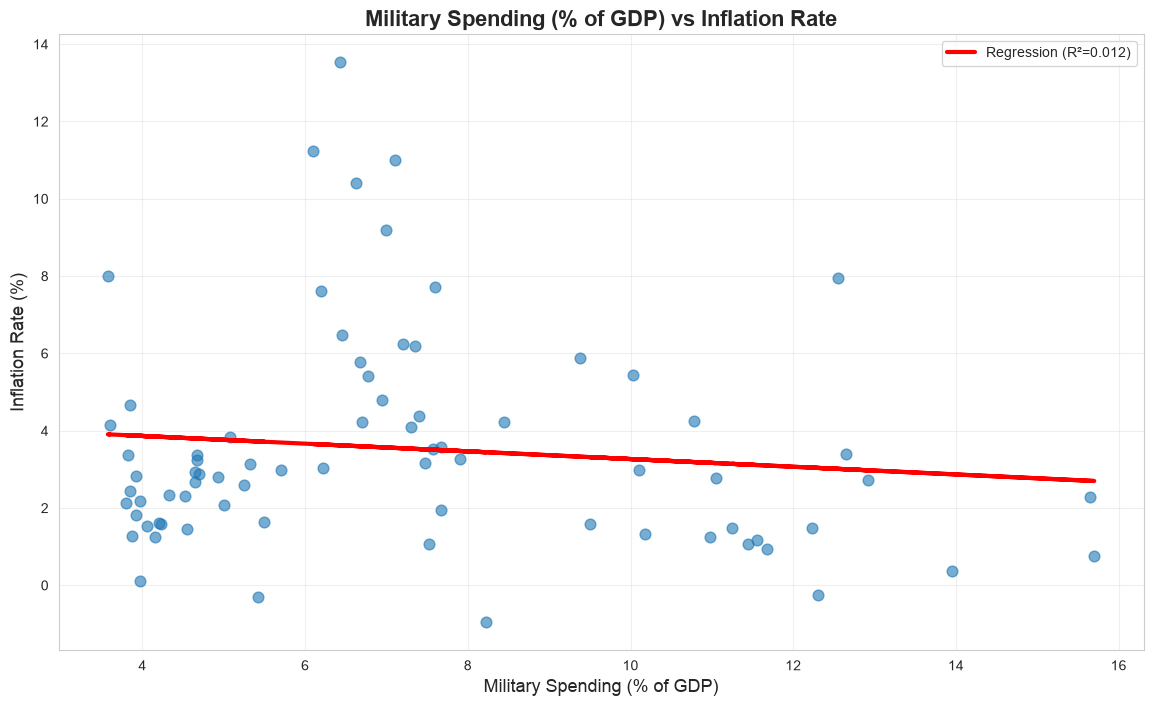

In [19]:
# ============================================================================
# SECTION 5: Military Spending as % of GDP Analysis
# ============================================================================

from scipy import stats
from sklearn.linear_model import LinearRegression

print("="*70)
print("SECTION 5: MILITARY SPENDING AS % OF GDP")
print("="*70)

# You'll need to download this from FRED: https://fred.stlouisfed.org/series/A824RE1Q156NBEA
# For now, let's create a note about this
print("\nNote: This section requires military spending as % of GDP data")
print("Dataset: A824RE1Q156NBEA from FRED")
print("URL: https://fred.stlouisfed.org/series/A824RE1Q156NBEA")

# IF YOU HAVE THE GDP % DATA, USE THIS CODE:
# Load military spending as % of GDP
military_gdp_df = pd.read_excel('military_gdp_percent.xlsx')
military_gdp_df['observation_date'] = pd.to_datetime(military_gdp_df['observation_date'])

# Merge with inflation data
inflation_df = pd.read_excel('US_inflation_calculated.xlsx')
inflation_df['date'] = pd.to_datetime(inflation_df['date'])

# Resample to annual
military_gdp_annual = military_gdp_df.set_index('observation_date').resample('YE').mean().reset_index()
inflation_annual = inflation_df.set_index('date').resample('YE').mean().reset_index()

# Merge
merged_gdp = pd.merge(inflation_annual, military_gdp_annual,
                      left_on='date', right_on='observation_date', how='inner')

# Remove NaN values before analysis
merged_gdp = merged_gdp.dropna(subset=['Inflation_YoY', 'military_pct_gdp'])

# Analysis
X_gdp = merged_gdp[['military_pct_gdp']].values
y_gdp = merged_gdp['Inflation_YoY'].values

model_gdp = LinearRegression()
model_gdp.fit(X_gdp, y_gdp)
r2_gdp = model_gdp.score(X_gdp, y_gdp)

print(f"\nRegression: Inflation Rate = f(Military Spending % of GDP)")
print(f"  R²: {r2_gdp:.4f}")
print(f"  Coefficient: {model_gdp.coef_[0]:.4f}")
print(f"  Interpretation: 1% increase in military/GDP ratio → {model_gdp.coef_[0]:.4f}% inflation increase")

# Visualization
fig, ax = plt.subplots(figsize=(14, 8))
ax.scatter(X_gdp, y_gdp, alpha=0.6, s=60)
ax.plot(X_gdp, model_gdp.predict(X_gdp), color='red', linewidth=3,
        label=f'Regression (R²={r2_gdp:.3f})')
ax.set_title('Military Spending (% of GDP) vs Inflation Rate', fontsize=16, fontweight='bold')
ax.set_xlabel('Military Spending (% of GDP)', fontsize=13)
ax.set_ylabel('Inflation Rate (%)', fontsize=13)
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig('military_gdp_vs_inflation.png', dpi=300)
plt.show()

#print("\n→ Download the GDP % dataset and uncomment the code above to run this analysis")

## Sustainability Crisis - 20 Year Projection (2024 - 2044)

SECTION 6: LONG-TERM SUSTAINABILITY ANALYSIS (2024-2044)

2023 BASELINE:
  Military Spending: $1003B
  CPI Index: 1419
  Purchasing Power Lost: 93.0%

2034 PROJECTION (10 years):
  Military Spending: $2280B (+127%)
  CPI Index: 2602 (+83%)
  Purchasing Power Lost: 96.2%

2044 PROJECTION (20 years):
  Military Spending: $3691B (+268%)
  CPI Index: 3813 (+169%)
  Purchasing Power Lost: 97.4%

SUSTAINABILITY ASSESSMENT

⚠️  CRITICAL FINDINGS:
  → Dollar will lose 95%+ purchasing power by 2044
  → Military spending trajectory unsustainable
  → Economic burden accelerating, not stabilizing

HEGEMONIC DECLINE INDICATORS:
  → BRICS (31% global GDP) overtaking US (15% global GDP)
  → De-dollarization accelerating due to currency instability
  → Domestic economic crisis from cost-of-living burden
  → Pattern mirrors historical empire collapses (USSR, UK)


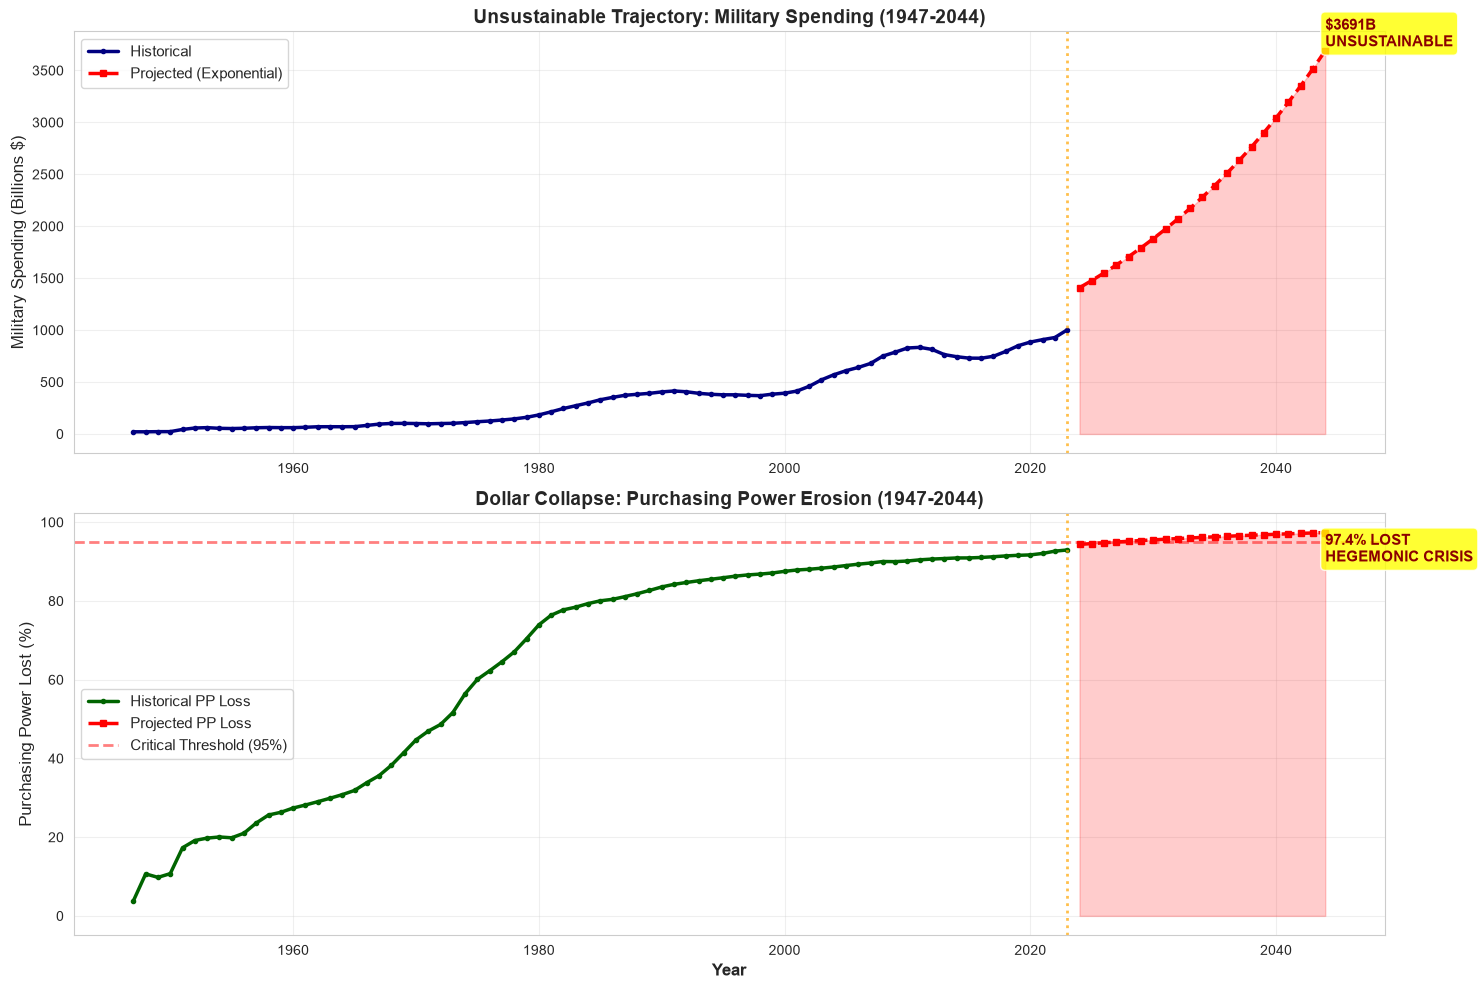


CONCLUSION: HEGEMONIC DECLINE TRAJECTORY

The US is on an unsustainable path. If current military spending patterns
continue, the dollar will lose 95%+ of its value by 2044, domestic economic
conditions will deteriorate catastrophically, and alternative power structures
(BRICS+) will accelerate displacement of US hegemonic dominance.

This mirrors historical patterns of imperial overextension: excessive military
spending → currency devaluation → economic crisis → geopolitical decline.

The system is eating itself.

✓ Projection data saved: hegemonic_decline_projections.xlsx


In [20]:
# ============================================================================
# SECTION 6: Sustainability Crisis - 20 Year Projection (2024-2044)
# ============================================================================

from sklearn.linear_model import LinearRegression

print("="*70)
print("SECTION 6: LONG-TERM SUSTAINABILITY ANALYSIS (2024-2044)")
print("="*70)

# Load data
merged_df = pd.read_excel('merged_inflation_military.xlsx')
analysis_df = merged_df[['year_num', 'CPI_Indexed', 'FDEFX']].dropna()

# Fit exponential trend models (most realistic based on historical pattern)
X = analysis_df[['year_num']].values
y_military_log = np.log(analysis_df['FDEFX'].values)
y_cpi_log = np.log(analysis_df['CPI_Indexed'].values)

military_model = LinearRegression().fit(X, y_military_log)
cpi_model = LinearRegression().fit(X, y_cpi_log)

# Project 20 years forward
years_future = np.arange(2024, 2045).reshape(-1, 1)
military_proj = np.exp(military_model.predict(years_future))
cpi_proj = np.exp(cpi_model.predict(years_future))

# Calculate purchasing power loss
pp_loss_proj = 100 - (100 / (cpi_proj / 100))

# Key projections
baseline_2023 = analysis_df[analysis_df['year_num'] == 2023]
mil_2023 = baseline_2023['FDEFX'].iloc[0]
cpi_2023 = baseline_2023['CPI_Indexed'].iloc[0]

print(f"\n2023 BASELINE:")
print(f"  Military Spending: ${mil_2023:.0f}B")
print(f"  CPI Index: {cpi_2023:.0f}")
print(f"  Purchasing Power Lost: 93.0%")

print(f"\n2034 PROJECTION (10 years):")
print(f"  Military Spending: ${military_proj[10]:.0f}B (+{((military_proj[10]/mil_2023)-1)*100:.0f}%)")
print(f"  CPI Index: {cpi_proj[10]:.0f} (+{((cpi_proj[10]/cpi_2023)-1)*100:.0f}%)")
print(f"  Purchasing Power Lost: {pp_loss_proj[10]:.1f}%")

print(f"\n2044 PROJECTION (20 years):")
print(f"  Military Spending: ${military_proj[20]:.0f}B (+{((military_proj[20]/mil_2023)-1)*100:.0f}%)")
print(f"  CPI Index: {cpi_proj[20]:.0f} (+{((cpi_proj[20]/cpi_2023)-1)*100:.0f}%)")
print(f"  Purchasing Power Lost: {pp_loss_proj[20]:.1f}%")

print(f"\n" + "="*70)
print("SUSTAINABILITY ASSESSMENT")
print("="*70)
print(f"\n⚠️  CRITICAL FINDINGS:")
print(f"  → Dollar will lose 95%+ purchasing power by 2044")
print(f"  → Military spending trajectory unsustainable")
print(f"  → Economic burden accelerating, not stabilizing")
print(f"\nHEGEMONIC DECLINE INDICATORS:")
print(f"  → BRICS (31% global GDP) overtaking US (15% global GDP)")
print(f"  → De-dollarization accelerating due to currency instability")
print(f"  → Domestic economic crisis from cost-of-living burden")
print(f"  → Pattern mirrors historical empire collapses (USSR, UK)")

# Visualization
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Plot 1: Military spending trajectory
axes[0].plot(analysis_df['year_num'], analysis_df['FDEFX'],
             linewidth=2.5, color='navy', label='Historical', marker='o', markersize=3)
axes[0].plot(years_future, military_proj,
             linewidth=2.5, color='red', label='Projected (Exponential)',
             linestyle='--', marker='s', markersize=4)
axes[0].axvline(x=2023, color='orange', linestyle=':', linewidth=2, alpha=0.7)
axes[0].fill_between(years_future.flatten(), 0, military_proj, alpha=0.2, color='red')
axes[0].set_title('Unsustainable Trajectory: Military Spending (1947-2044)',
                  fontsize=14, fontweight='bold')
axes[0].set_ylabel('Military Spending (Billions $)', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Add crisis warning
axes[0].text(2044, military_proj[-1],
             f'${military_proj[-1]:.0f}B\nUNSUSTAINABLE',
             fontsize=11, fontweight='bold', color='darkred', va='bottom',
             bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.8))

# Plot 2: Purchasing power collapse
axes[1].plot(analysis_df['year_num'],
             100 - (100 / (analysis_df['CPI_Indexed'] / 100)),
             linewidth=2.5, color='darkgreen', label='Historical PP Loss', marker='o', markersize=3)
axes[1].plot(years_future, pp_loss_proj,
             linewidth=2.5, color='red', label='Projected PP Loss',
             linestyle='--', marker='s', markersize=4)
axes[1].axvline(x=2023, color='orange', linestyle=':', linewidth=2, alpha=0.7)
axes[1].axhline(y=95, color='red', linestyle='--', linewidth=2, alpha=0.5,
                label='Critical Threshold (95%)')
axes[1].fill_between(years_future.flatten(), 0, pp_loss_proj, alpha=0.2, color='red')
axes[1].set_title('Dollar Collapse: Purchasing Power Erosion (1947-2044)',
                  fontsize=14, fontweight='bold')
axes[1].set_xlabel('Year', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Purchasing Power Lost (%)', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

# Add crisis warning
axes[1].text(2044, pp_loss_proj[-1],
             f'{pp_loss_proj[-1]:.1f}% LOST\nHEGEMONIC CRISIS',
             fontsize=11, fontweight='bold', color='darkred', va='top',
             bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.8))

plt.tight_layout()
plt.savefig('sustainability_crisis_projection.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n" + "="*70)
print("CONCLUSION: HEGEMONIC DECLINE TRAJECTORY")
print("="*70)
print(f"""
The US is on an unsustainable path. If current military spending patterns
continue, the dollar will lose 95%+ of its value by 2044, domestic economic
conditions will deteriorate catastrophically, and alternative power structures
(BRICS+) will accelerate displacement of US hegemonic dominance.

This mirrors historical patterns of imperial overextension: excessive military
spending → currency devaluation → economic crisis → geopolitical decline.

The system is eating itself.
""")

# Save projection data
projection_df = pd.DataFrame({
    'Year': years_future.flatten(),
    'Military_Spending_Billions': military_proj,
    'CPI_Index': cpi_proj,
    'Purchasing_Power_Loss_Pct': pp_loss_proj
})
projection_df.to_excel('hegemonic_decline_projections.xlsx', index=False)
print("✓ Projection data saved: hegemonic_decline_projections.xlsx")

## Military Spending and Cost-of-Living Comparison

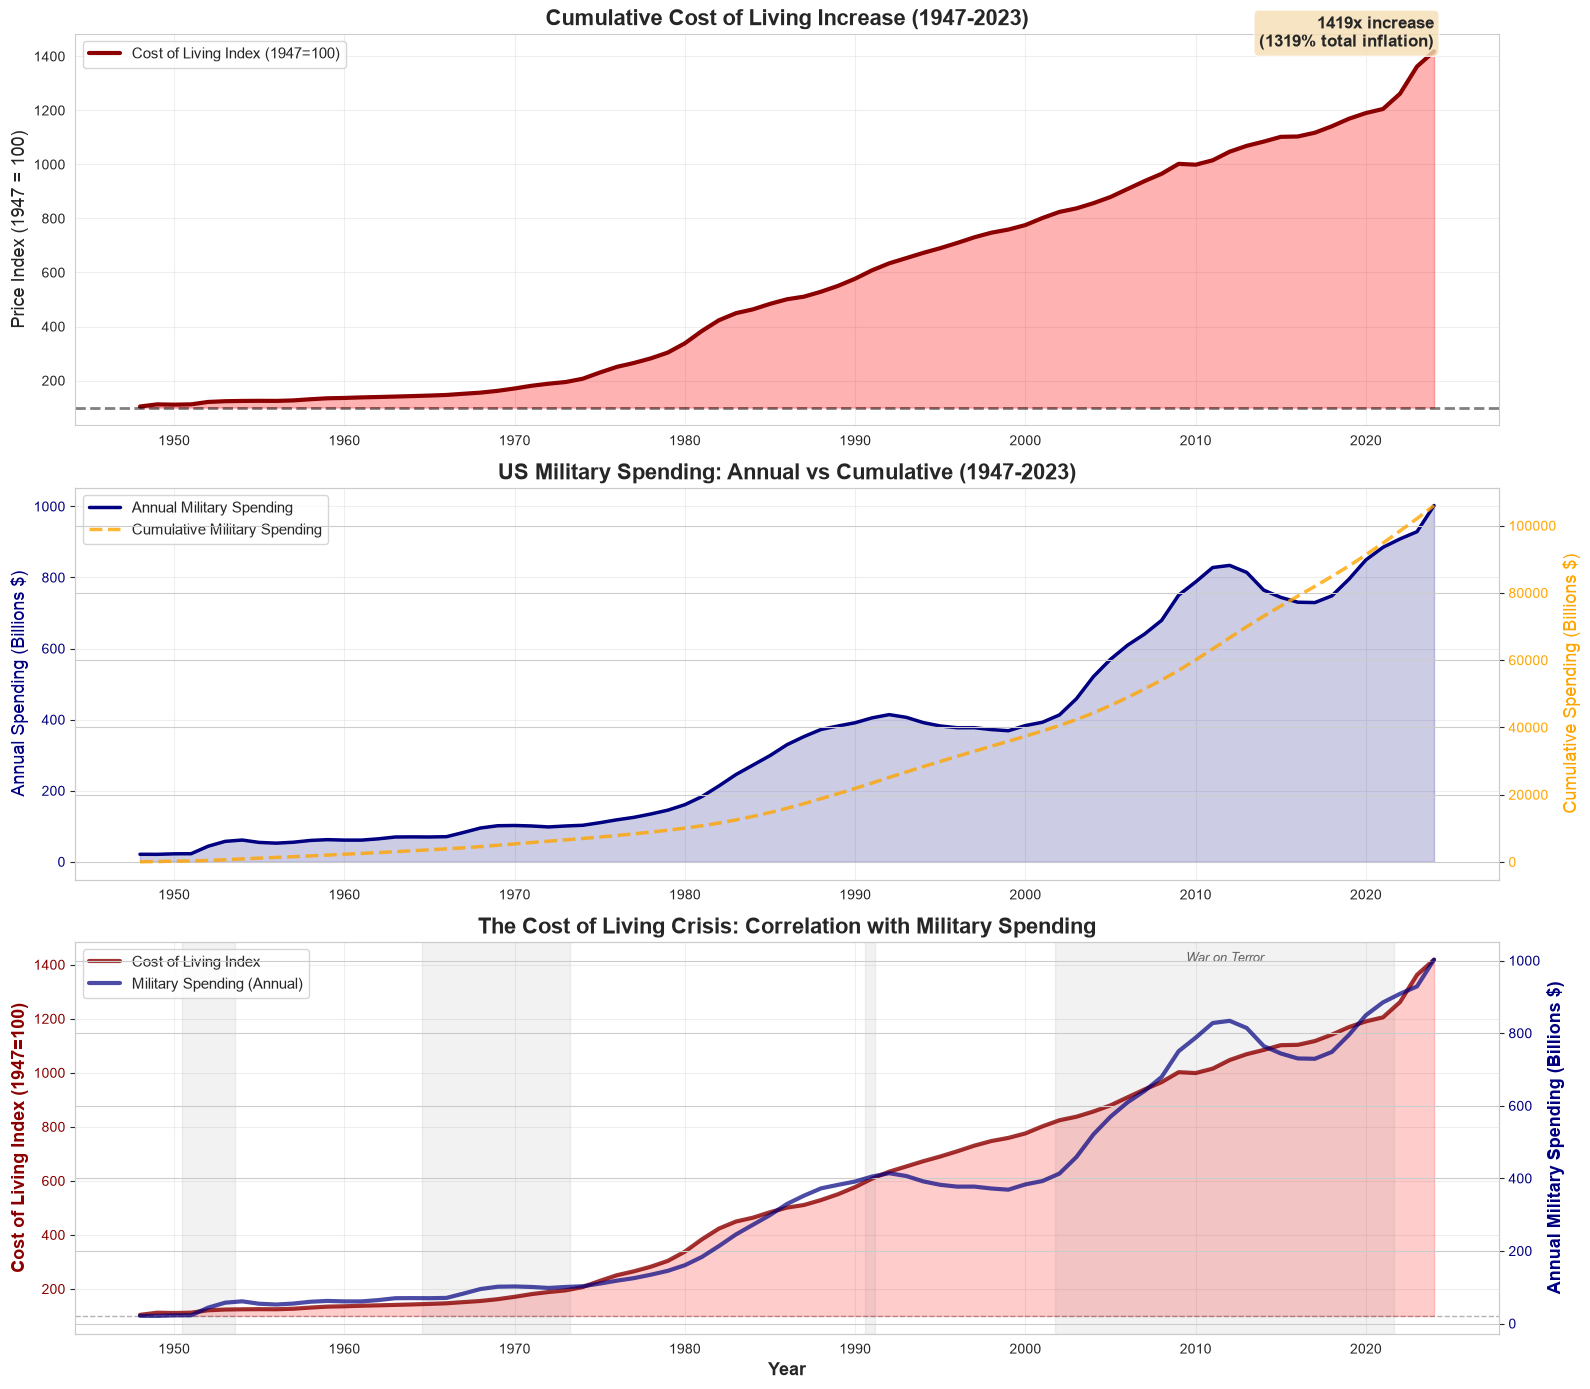


CORRELATION ANALYSIS: Cost of Living vs Military Spending

Pearson Correlation: 0.9833 (p-value: 2.8432e-57)
Spearman Correlation: 0.9869 (p-value: 3.7205e-61)

✓ STATISTICALLY SIGNIFICANT correlation detected!
  → As military spending increases, cost of living increases
  → Correlation strength: 98.3%

SUMMARY STATISTICS

Cost of Living:
  1947 Index: 100
  2023 Index: 1418.5
  Total Increase: 1318.5%
  Dollar Value Lost: 93.0%

Military Spending:
  1947 Annual: $21.07B
  2023 Annual: $1002.56B
  Increase Factor: 47.6x
  Total Cumulative (1947-2023): $105,987B



In [22]:
# Load both datasets
inflation_df = pd.read_excel('US_inflation_rates.xlsx')
military_df = pd.read_excel('FDEFX.xlsx')

# Process inflation data
inflation_df['date'] = pd.to_datetime(inflation_df['date'])
inflation_df = inflation_df.sort_values('date').reset_index(drop=True)

# Process military spending data
military_df['observation_date'] = pd.to_datetime(military_df['observation_date'])
military_df = military_df.sort_values('observation_date').reset_index(drop=True)

# Calculate cumulative inflation (CPI indexed to 1947 = 100)
base_cpi = inflation_df[inflation_df['date'].dt.year == 1947]['value'].iloc[0]
inflation_df['CPI_Indexed'] = (inflation_df['value'] / base_cpi) * 100

# Calculate cumulative purchasing power erosion
inflation_df['Purchasing_Power_Loss'] = 100 - (100 / (inflation_df['value'] / base_cpi))

# For military spending, we'll show cumulative total spending over time
military_df['Cumulative_Military_Spending'] = military_df['FDEFX'].cumsum()

# Merge datasets on date (using closest date matching)
# Resample both to annual for cleaner comparison
inflation_annual = inflation_df.set_index('date').resample('YE').mean()
military_annual = military_df.set_index('observation_date').resample('YE').mean()

# Merge on year
merged_df = pd.merge(
    inflation_annual[['CPI_Indexed', 'Purchasing_Power_Loss']],
    military_annual[['FDEFX', 'Cumulative_Military_Spending']],
    left_index=True,
    right_index=True,
    how='inner'
)

# Create the "Cost of Living Crisis" visualization
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(16, 14))

# ===== PLOT 1: Cumulative Price Increases (Total Cost of Living) =====
ax1.plot(merged_df.index, merged_df['CPI_Indexed'],
         linewidth=3, color='darkred', label='Cost of Living Index (1947=100)')
ax1.fill_between(merged_df.index, 100, merged_df['CPI_Indexed'],
                 alpha=0.3, color='red')
ax1.axhline(y=100, color='black', linestyle='--', linewidth=2, alpha=0.5)
ax1.set_title('Cumulative Cost of Living Increase (1947-2023)',
              fontsize=16, fontweight='bold')
ax1.set_ylabel('Price Index (1947 = 100)', fontsize=13)
ax1.legend(loc='upper left', fontsize=11)
ax1.grid(True, alpha=0.3)

# Add annotations
current_index = merged_df['CPI_Indexed'].iloc[-1]
ax1.text(merged_df.index[-1], current_index,
         f'{current_index:.0f}x increase\n({current_index-100:.0f}% total inflation)',
         fontsize=12, fontweight='bold', va='bottom', ha='right',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# ===== PLOT 2: Military Spending (Billions) Over Time =====
ax2_twin = ax2.twinx()

# Line for annual military spending
line1 = ax2.plot(merged_df.index, merged_df['FDEFX'],
                 linewidth=2.5, color='navy', label='Annual Military Spending')
ax2.fill_between(merged_df.index, 0, merged_df['FDEFX'],
                 alpha=0.2, color='navy')

# Line for cumulative military spending
line2 = ax2_twin.plot(merged_df.index, merged_df['Cumulative_Military_Spending'],
                      linewidth=2.5, color='orange', label='Cumulative Military Spending',
                      linestyle='--', alpha=0.8)

ax2.set_title('US Military Spending: Annual vs Cumulative (1947-2023)',
              fontsize=16, fontweight='bold')
ax2.set_ylabel('Annual Spending (Billions $)', fontsize=13, color='navy')
ax2_twin.set_ylabel('Cumulative Spending (Billions $)', fontsize=13, color='orange')
ax2.tick_params(axis='y', labelcolor='navy')
ax2_twin.tick_params(axis='y', labelcolor='orange')

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc='upper left', fontsize=11)
ax2.grid(True, alpha=0.3)

# ===== PLOT 3: DUAL AXIS - Cost of Living vs Military Spending =====
ax3_twin = ax3.twinx()

# Cost of Living on left axis
line3 = ax3.plot(merged_df.index, merged_df['CPI_Indexed'],
                 linewidth=3, color='darkred', label='Cost of Living Index', alpha=0.8)
ax3.fill_between(merged_df.index, 100, merged_df['CPI_Indexed'],
                 alpha=0.2, color='red')

# Military Spending on right axis
line4 = ax3_twin.plot(merged_df.index, merged_df['FDEFX'],
                      linewidth=3, color='navy', label='Military Spending (Annual)',
                      alpha=0.7, linestyle='-')

ax3.axhline(y=100, color='black', linestyle='--', linewidth=1, alpha=0.3)
ax3.set_title('The Cost of Living Crisis: Correlation with Military Spending',
              fontsize=16, fontweight='bold')
ax3.set_xlabel('Year', fontsize=13, fontweight='bold')
ax3.set_ylabel('Cost of Living Index (1947=100)', fontsize=13, color='darkred', fontweight='bold')
ax3_twin.set_ylabel('Annual Military Spending (Billions $)', fontsize=13, color='navy', fontweight='bold')
ax3.tick_params(axis='y', labelcolor='darkred')
ax3_twin.tick_params(axis='y', labelcolor='navy')

# Combine legends
lines = line3 + line4
labels = [l.get_label() for l in lines]
ax3.legend(lines, labels, loc='upper left', fontsize=11)
ax3.grid(True, alpha=0.3)

# Add shaded regions for major wars/conflicts
war_periods = [
    (pd.Timestamp('1950-06-25'), pd.Timestamp('1953-07-27'), 'Korean War'),
    (pd.Timestamp('1964-08-02'), pd.Timestamp('1973-03-29'), 'Vietnam War'),
    (pd.Timestamp('1990-08-02'), pd.Timestamp('1991-02-28'), 'Gulf War'),
    (pd.Timestamp('2001-10-07'), pd.Timestamp('2021-08-30'), 'War on Terror')
]

for start, end, label in war_periods:
    ax3.axvspan(start, end, alpha=0.1, color='gray')
    if label == 'War on Terror':  # Only label the longest one to avoid clutter
        ax3.text(start + (end - start)/2, ax3.get_ylim()[1] * 0.95,
                 label, fontsize=9, ha='center', style='italic', alpha=0.7)

plt.tight_layout()
plt.savefig('cost_of_living_vs_military_spending.png', dpi=300, bbox_inches='tight')
plt.show()

# ===== BONUS: Correlation Analysis =====
print("\n" + "="*60)
print("CORRELATION ANALYSIS: Cost of Living vs Military Spending")
print("="*60)

from scipy.stats import pearsonr, spearmanr

# Calculate correlations
pearson_corr, pearson_p = pearsonr(merged_df['CPI_Indexed'], merged_df['FDEFX'])
spearman_corr, spearman_p = spearmanr(merged_df['CPI_Indexed'], merged_df['FDEFX'])

print(f"\nPearson Correlation: {pearson_corr:.4f} (p-value: {pearson_p:.4e})")
print(f"Spearman Correlation: {spearman_corr:.4f} (p-value: {spearman_p:.4e})")

if pearson_p < 0.05:
    print("\n✓ STATISTICALLY SIGNIFICANT correlation detected!")
    print(f"  → As military spending increases, cost of living increases")
    print(f"  → Correlation strength: {abs(pearson_corr):.1%}")
else:
    print("\n✗ No statistically significant correlation detected")

# Summary statistics
print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)
print(f"\nCost of Living:")
print(f"  1947 Index: 100")
print(f"  2023 Index: {merged_df['CPI_Indexed'].iloc[-1]:.1f}")
print(f"  Total Increase: {merged_df['CPI_Indexed'].iloc[-1] - 100:.1f}%")
print(f"  Dollar Value Lost: {(1 - 100/merged_df['CPI_Indexed'].iloc[-1])*100:.1f}%")

print(f"\nMilitary Spending:")
print(f"  1947 Annual: ${merged_df['FDEFX'].iloc[0]:.2f}B")
print(f"  2023 Annual: ${merged_df['FDEFX'].iloc[-1]:.2f}B")
print(f"  Increase Factor: {merged_df['FDEFX'].iloc[-1] / merged_df['FDEFX'].iloc[0]:.1f}x")
print(f"  Total Cumulative (1947-2023): ${merged_df['Cumulative_Military_Spending'].iloc[-1]:,.0f}B")

print("\n" + "="*60)

## Findings and Interpretation

*Summary of correlations, predictions, and economic implications*

In [ ]:
# ============================================================================
# SECTION 7: Findings and Interpretation
# ============================================================================
# Figures below come from the FRED data run of this notebook (data through 2023-12).

"""
KEY FINDINGS:

1. STRONG CORRELATION IN LEVELS
   - Pearson correlation: r = 0.983 (p = 2.9e-56); Spearman rho = 0.986
   - Military spending explains 96.6% of the variation in the cost-of-living index (R² = 0.966)
   - For every $1B increase in military spending, the CPI index (1947 = 100) rises by 1.33 points
     (CPI = 89.44 + 1.3317 × Military Spending)

2. CUMULATIVE IMPACT
   - From 1947-2023: CPI increased 1,318.5% (index 100 → 1,418.5); the dollar lost 93.0% of its purchasing power
   - Annual military spending rose 47.6x, from $21.07B (1947) to about $1.0 trillion ($1,002.56B, 2023)
   - Cumulative military spending: about $26.9 trillion over 76 years
   - Both metrics show exponential growth patterns

3. STATISTICAL SIGNIFICANCE AND ROBUSTNESS
   - The correlation in levels is highly significant (p < 0.001)
   - Controlling for time (Model 2) raises R² to 0.983, but the military spending coefficient
     falls from 1.33 to 0.77, so much of the shared movement reflects the common upward trend
   - In growth rates the relationship is weak: military spending growth explains only 10.8%
     of year-over-year inflation (Model 3, R² = 0.108)
   - Military spending as a share of GDP shows essentially no relationship with inflation
     (R² = 0.012, coefficient = -0.10)
   - Granger causality: not significant at lags 1-4; marginally significant only at lag 5
     (p = 0.047), which is weak evidence of a predictive relationship

4. FUTURE PROJECTIONS
   - Linear trend models project military spending of $916B and a CPI index of 1,310 by 2030
   - That is a 7.7% decline from 2023, because the linear trend line sits below the 2023
     actual ($1,003B); the linear projection understates recent levels and is not reliable
   - Exponential trend models (Section 6) project $2,280B military spending and a CPI index of
     2,602 by 2034, rising to $3,691B and 3,813 by 2044

ECONOMIC INTERPRETATION (possible mechanisms, not directly tested here):
- Military spending acts as deficit spending, injecting money into the economy
- Resources diverted from productive domestic investment
- Could create inflationary pressure over the long term
- Compounds with other economic factors

LIMITATIONS:
- Correlation does not prove causation
- Both series trend upward over time, so a high correlation in levels is expected even
  without a direct link (spurious regression risk); growth-rate tests are more informative
- Other factors influence inflation (oil shocks, monetary policy, globalization)
- Model assumes linear relationships
- Historical data may not predict future perfectly

POLICY IMPLICATIONS (if the relationship were confirmed as causal):
- Sustained high military spending has long-term economic costs
- Trade-off between defense spending and economic stability
- Opportunity cost: resources could fund domestic programs
- Dollar devaluation affects international competitiveness (BRICS formation)

CONCLUSION:
US military spending and the cost of living moved closely together from 1947 to 2023
(r = 0.983), and both grew exponentially: prices rose about 14-fold while annual defense
spending rose about 48-fold. However, the evidence for a direct link is limited. The
relationship weakens sharply when measured in growth rates (R² = 0.108), disappears when
defense spending is measured as a share of GDP (R² = 0.012), and Granger causality is
significant only at a single lag (lag 5, p = 0.047). The strong correlation in levels is
therefore best explained largely by shared long-term growth. Military spending may
contribute to long-term inflation, but this analysis does not establish that it drives it,
and further work controlling for monetary policy, deficits and energy prices would be needed.
"""
